## Run instructions

1. Restart the kernel and use **Run All** in the environment that ran v2.
2. Check the GPU name, date coverage, purging audit, and unfinished-work runtime estimate before the long loops.
3. Keep the machine plugged in and prevent sleep. Resume by running all cells again; an identical configuration and cached data reuse completed v3 work.
4. The 2026 fold is partial. Full-year-only and class-distribution sensitivity results are printed separately.
5. `SYNTHETIC_TEST=True` is a small offline integration check, not scientific evidence.

The raw OHLC snapshot is cached in v3. Changing settings creates a different result directory. Do not copy v2 checkpoint CSVs into it.


In [1]:
import os
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"   # must be set before importing torch

import time, random, warnings, json, hashlib, platform, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
import pywt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.models as models
from torch.utils.data import DataLoader, TensorDataset
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression, LogisticRegressionCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score, accuracy_score, make_scorer
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf
warnings.filterwarnings("default")  # preserve convergence and numerical warnings

# ---------------- configuration ----------------
SYNTHETIC_TEST = False        # True = tiny synthetic run to check the notebook end to end (no internet, no GPU)

RUN_TASK_SEEDS    = True      # task 1: multi-seed main comparison
RUN_TASK_VOLSCAL  = True      # task 2: scalogram of the volatility series
RUN_TASK_PROBING  = True      # task 3: fixed-dimension probing + random-network control

SEEDS = [42, 1337, 2024]      # seed 42 is re-run too, so every seed comes from the same machine
VOLSCAL_SEEDS = SEEDS.copy()  # [42] is shorter but provisional
PROBE_MARKETS = ["S&P 500 (US)", "KOSPI (Korea)"]
PROBE_YEARS = [2024, 2025, 2026]
PROBE_DIM = 32                # same dimension for every layer
CV_GAP = 20
MAIN_ENCODINGS = ["gasf", "scalogram", "gasf_lvl", "scal_lvl"]
VOL_ENCODINGS = ["vol_scalogram", "vol_scal_lvl"]
RUN_TASK_STACK = True
RUN_POSTHOC = True
MAX_LEVERAGE = 2.0            # pre-specified cap; financing and costs excluded
DETERMINISTIC = False         # seeds set; CUDA bitwise reproducibility not guaranteed

MARKETS = {
    "S&P 500 (US)": "^GSPC",
    "EuroStoxx50 (EU)": "^STOXX50E",
    "KOSPI (Korea)": "^KS11",
    "Shanghai Composite (China)": "000001.SS",
}
START, END = "2010-01-01", "2026-06-30"
WINDOW = 64                   # 64-day window, 64x64 images
H = 20                        # forward horizon and Yang-Zhang window
EPOCHS = 10
BATCH_SIZE = 32
LR = 5e-5
RESNET_INPUT = 224            # ResNet18 input size after upsampling
PRETRAINED = True
FIRST_TEST_YEAR, LAST_TEST_YEAR = 2015, 2026
MIN_TRAIN_DAYS = 750
LABEL_LOOKBACK_YEARS = 5

if SYNTHETIC_TEST:
    MARKETS = {"SYN-A": "SYN-A", "SYN-B": "SYN-B"}
    SEEDS, VOLSCAL_SEEDS = [42, 7], [42]
    PROBE_MARKETS, PROBE_YEARS = ["SYN-A"], [2021, 2022]
    FIRST_TEST_YEAR, LAST_TEST_YEAR = 2021, 2022
    MIN_TRAIN_DAYS, EPOCHS, RESNET_INPUT, PRETRAINED = 400, 1, 64, False
    PROBE_DIM, CV_GAP = 8, H

if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

torch.backends.cudnn.benchmark = (device.type == "cuda" and not DETERMINISTIC)
torch.backends.cudnn.deterministic = DETERMINISTIC
USE_AMP = device.type == "cuda"
if DETERMINISTIC: torch.use_deterministic_algorithms(True, warn_only=True)
print("device:", device, "GPU:", torch.cuda.get_device_name(0) if device.type == "cuda" else "n/a")

BASE_DIR = os.path.abspath(".")
config = dict(protocol="quality-v3", markets=MARKETS, start=START, end=END, window=WINDOW,
              horizon=H, epochs=EPOCHS, batch=BATCH_SIZE, lr=LR, input_size=RESNET_INPUT,
              pretrained=PRETRAINED, seeds=SEEDS, vol_seeds=VOLSCAL_SEEDS,
              first_year=FIRST_TEST_YEAR, last_year=LAST_TEST_YEAR, min_train=MIN_TRAIN_DAYS,
              label_lookback=LABEL_LOOKBACK_YEARS, probe_dim=PROBE_DIM, cv_gap=CV_GAP,
              max_leverage=MAX_LEVERAGE, deterministic=DETERMINISTIC, synthetic=SYNTHETIC_TEST)
CONFIG_ID = hashlib.sha256(json.dumps(config, sort_keys=True).encode()).hexdigest()[:12]
ROOT_DIR = os.path.join(BASE_DIR, "quality_v3" + ("_synthetic" if SYNTHETIC_TEST else ""))
RUN_DIR = os.path.join(ROOT_DIR, CONFIG_ID)
CKPT_DIR, PRED_DIR = (os.path.join(RUN_DIR, k) for k in ("checkpoints", "predictions"))
CACHE_DIR, DATA_DIR = (os.path.join(ROOT_DIR, k) for k in ("image_cache", "data"))
for folder in (CKPT_DIR, PRED_DIR, CACHE_DIR, DATA_DIR): os.makedirs(folder, exist_ok=True)
manifest = dict(config=config, python=sys.version, platform=platform.platform(),
                torch=torch.__version__, sklearn=__import__("sklearn").__version__,
                gpu=torch.cuda.get_device_name(0) if device.type == "cuda" else str(device))
Path(RUN_DIR, "manifest.json").write_text(json.dumps(manifest, indent=2))
print("configuration:", CONFIG_ID, "results ->", RUN_DIR)

def ckpt_path(name): return os.path.join(CKPT_DIR, f"{name}.csv")
def load_ckpt(name):
    p = ckpt_path(name)
    return pd.read_csv(p) if os.path.exists(p) else pd.DataFrame()
def done_keys(name, cols):
    df = load_ckpt(name)
    return set() if df.empty else set(map(tuple, df[cols].astype(str).values.tolist()))
def append_ckpt(name, row):
    # Rewrite atomically: an interrupted append must not leave a partial CSV row.
    p = ckpt_path(name); df = load_ckpt(name)
    df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)
    tmp = p + ".tmp"; df.to_csv(tmp, index=False); os.replace(tmp, p)
def upsert_block(name, rows, keys):
    fresh = pd.DataFrame(rows); old = load_ckpt(name)
    all_rows = pd.concat([old, fresh], ignore_index=True).drop_duplicates(keys, keep="last")
    p = ckpt_path(name); tmp = p + ".tmp"; all_rows.to_csv(tmp, index=False); os.replace(tmp, p)
def save_npy(path, values):
    tmp = path + ".tmp"
    with open(tmp, "wb") as fh: np.save(fh, values)
    os.replace(tmp, path)
def save_npz(path, **values):
    tmp = path + ".tmp"
    with open(tmp, "wb") as fh: np.savez_compressed(fh, **values)
    os.replace(tmp, path)
def _tag(name): return MARKETS[name].replace("^", "").replace("/", "_")
def bpath(name, year, seed): return os.path.join(PRED_DIR, f"base_{_tag(name)}_{year}_{seed}.npz")
def ipath(name, year, seed, enc, arch): return os.path.join(PRED_DIR, f"img_{_tag(name)}_{year}_{seed}_{enc}_{arch}.npy")

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

def clear_memory():
    if device.type == "mps": torch.mps.empty_cache()
    elif device.type == "cuda": torch.cuda.empty_cache()


device: cuda GPU: NVIDIA GeForce RTX 5060 Laptop GPU
configuration: e218013cc743 results -> C:\Users\Asus\Downloads\quality_v3\e218013cc743


## 1. Data, targets, folds

In [2]:
def _synthetic_ohlc(name, n=1800):
    rng = np.random.default_rng(sum(map(ord, name)))
    dates = pd.bdate_range("2016-01-01", periods=n)
    vol = 0.01 * np.exp(np.convolve(rng.normal(0, 0.35, n), np.ones(30) / 30, mode="same"))
    close = 100 * np.exp(np.cumsum(rng.normal(0, 1, n) * vol))
    op = close * (1 + rng.normal(0, 0.002, n))
    hi = np.maximum(op, close) * (1 + np.abs(rng.normal(0, 0.004, n)))
    lo = np.minimum(op, close) * (1 - np.abs(rng.normal(0, 0.004, n)))
    return pd.DataFrame({"Open": op, "High": hi, "Low": lo, "Close": close}, index=dates)

def fetch_ohlc(ticker, retries=3, delay=8):
    if SYNTHETIC_TEST:
        return _synthetic_ohlc(ticker)
    snapshot = Path(DATA_DIR) / f"{ticker.replace(chr(94), chr(95))}_{START}_{END}.csv"
    if snapshot.exists():
        return pd.read_csv(snapshot, index_col=0, parse_dates=True)
    last = None
    for a in range(retries):
        try:
            raw = yf.download(ticker, start=START, end=END, auto_adjust=True, progress=False, timeout=30)
            if isinstance(raw.columns, pd.MultiIndex):
                l0, l1 = raw.columns.get_level_values(0), raw.columns.get_level_values(1)
                if ticker in l1: raw = raw.xs(ticker, axis=1, level=1)
                elif ticker in l0: raw = raw.xs(ticker, axis=1, level=0)
                else: raw.columns = l0
            df = raw[["Open", "High", "Low", "Close"]].dropna()
            if len(df) == 0: raise ValueError("empty")
            tmp = str(snapshot) + ".tmp"; df.to_csv(tmp); os.replace(tmp, snapshot)
            return df
        except Exception as e:
            last = e; print(f"  {ticker}: attempt {a+1} failed ({e})"); time.sleep(delay)
    raise RuntimeError(f"{ticker}: could not download ({last})")

def yang_zhang_vol(o, window=H):
    O, Hh, L, Cc = o["Open"], o["High"], o["Low"], o["Close"]
    oo = np.log(O / Cc.shift(1)); cc = np.log(Cc / O)
    rs = np.log(Hh / Cc) * np.log(Hh / O) + np.log(L / Cc) * np.log(L / O)
    k = 0.34 / (1.34 + (window + 1) / (window - 1))
    return np.sqrt(oo.rolling(window).var() + k * cc.rolling(window).var() + (1 - k) * rs.rolling(window).mean())

def daily_rs(o):
    rs = np.log(o["High"] / o["Close"]) * np.log(o["High"] / o["Open"]) + np.log(o["Low"] / o["Close"]) * np.log(o["Low"] / o["Open"])
    return rs.clip(lower=1e-10)

def parkinson_daily_vol(o):
    return np.sqrt(np.log(o["High"] / o["Low"]) ** 2 / (4 * np.log(2)))

def label_q(y, ql, qh):
    lab = np.ones(len(y), dtype=int); lab[y <= ql] = 0; lab[y > qh] = 2; return lab


def calendar_folds(idx, label_end):
    out = []
    for year in range(FIRST_TEST_YEAR, LAST_TEST_YEAR + 1):
        te = np.where((idx >= pd.Timestamp(f"{year}-01-01")) & (idx < pd.Timestamp(f"{year+1}-01-01")))[0]
        if not len(te): continue
        # Prediction at sample t uses information through its previous trading day.
        cutoff = idx[te[0]]  # label_end must be strictly before first test sample t
        raw_tr = np.where(idx < cutoff)[0]
        tr = raw_tr[label_end[raw_tr] < cutoff]
        if len(tr) < MIN_TRAIN_DAYS: continue
        assert label_end[tr].max() < idx[te[0]]
        out.append(dict(year=year, train_idx=tr, test_idx=te, train_end=idx[tr].max(),
                        purged=len(raw_tr)-len(tr), cutoff=cutoff))
    return out

def calib_idx(train_idx, idx, train_end):
    c = train_idx[idx[train_idx] >= train_end - pd.DateOffset(years=LABEL_LOOKBACK_YEARS)]
    return c if len(c) else train_idx


## 2. Encodings and strict timing

Every 64-day input window ends at t−1; targets cover (t,t+H]. RF, TCN, HAR and lagged persistence share the same information cutoff. A contemporaneous persistence reference is saved separately for diagnostic use and excluded from headline comparison.

Fixed-scale constants use only windows dated before the first test year. Clipping and magnitude-only transforms remain lossy. Separate cache keys include the data fingerprint, window size and calibration cutoff.


In [3]:
def gasf_batch(w):
    lo = w.min(1, keepdims=True); hi = w.max(1, keepdims=True); rng_ = hi - lo
    x = np.where(rng_ > 0, 2 * (w - lo) / np.where(rng_ > 0, rng_, 1) - 1, 0.0)
    x = np.clip(x, -1, 1); s = np.sqrt(np.clip(1 - x ** 2, 0, 1))
    return (x[:, :, None] * x[:, None, :] - s[:, :, None] * s[:, None, :]).astype(np.float32)

def scalogram_batch(w, chunk=1000):
    out = []
    for i in range(0, len(w), chunk):
        coef, _ = pywt.cwt(w[i:i + chunk], np.arange(1, WINDOW + 1), "morl", axis=-1)
        m = np.abs(coef).transpose(1, 0, 2)
        lo = m.min((1, 2), keepdims=True); hi = m.max((1, 2), keepdims=True); r_ = hi - lo
        out.append(np.where(r_ > 0, (m - lo) / np.where(r_ > 0, r_, 1), 0).astype(np.float32))
    return np.concatenate(out)

# ---- level-preserving encodings: FIXED constants from pre-test data (before first test year), no per-window rescaling ----
LVL = {}
def level_consts(name, key):
    k = (name, key)
    if k in LVL: return LVL[k]
    d = market_data(name); pre = d["idx"] < pd.Timestamp(f"{FIRST_TEST_YEAR}-01-01")
    W = d[key][pre]
    C = max(float(np.nanpercentile(np.abs(W), 99.5)), 1e-12)
    coef, _ = pywt.cwt(np.clip(W[::5] / C, -1, 1), np.arange(1, WINDOW + 1), "morl", axis=-1)
    LVL[k] = (C, max(float(np.percentile(np.abs(coef), 99)), 1e-12)); return LVL[k]

def gasf_lvl(w, C):
    x = np.clip(w / C, -1, 1); s = np.sqrt(np.clip(1 - x ** 2, 0, 1))
    return (x[:, :, None] * x[:, None, :] - s[:, :, None] * s[:, None, :]).astype(np.float32)

def scal_lvl(w, C, M0, chunk=1000):
    out = []
    for i in range(0, len(w), chunk):
        coef, _ = pywt.cwt(np.clip(w[i:i + chunk] / C, -1, 1), np.arange(1, WINDOW + 1), "morl", axis=-1)
        out.append(np.clip(np.abs(coef).transpose(1, 0, 2) / M0, 0, 1).astype(np.float32))
    return np.concatenate(out)

MARKET_DATA = {}
def market_data(name):
    if name in MARKET_DATA: return MARKET_DATA[name]
    o = fetch_ohlc(MARKETS[name])
    ret = np.log(o["Close"] / o["Close"].shift(1)).dropna()
    o = o.reindex(ret.index)
    vt = yang_zhang_vol(o).reindex(ret.index); vf = vt.shift(-H)
    rs = daily_rs(o).reindex(ret.index); pk = parkinson_daily_vol(o).reindex(ret.index)

    har_lag = np.column_stack([np.log(rs), np.log(rs.rolling(5).mean()), np.log(rs.rolling(22).mean())])
    t_all = np.arange(max(WINDOW, 23), len(ret) - H)
    ok = np.array([pd.notna(vf.iloc[t]) and pd.notna(vt.iloc[t-1]) and np.isfinite(har_lag[t-1]).all() and np.isfinite(pk.iloc[t - WINDOW:t]).all() for t in t_all])
    t_use = t_all[ok]
    r = ret.values
    ret_win = np.stack([r[t - WINDOW:t] for t in t_use])
    pk_win = np.stack([pk.values[t - WINDOW:t] for t in t_use])

    def tab(t):
        w = pd.Series(r[t - 20:t])
        return [w.mean(), w.std(), w.skew(), w.kurt(), w.autocorr(1)]
    d = dict(
        idx=ret.index[t_use],
        y_fwd=vf.values[t_use], y_trail=vt.values[t_use], y_trail_lag1=vt.values[t_use-1],
        X_har=har_lag[t_use-1], label_end=ret.index[t_use+H], info_end=ret.index[t_use-1],
        rs=rs.values, rs_pos=t_use,
        X_tab=np.nan_to_num(np.array([tab(t) for t in t_use])),
        X_seq=ret_win[:, None, :].astype(np.float32),
        ret_win=ret_win, pk_win=pk_win,
    )
    d["t_use"] = t_use
    d["fwd_ret"] = np.array([r[t + 1:t + H + 1].sum() for t in t_use])   # return over the same window as the label
    d["folds"] = calendar_folds(d["idx"], d["label_end"])
    d["data_id"] = hashlib.sha256(pd.util.hash_pandas_object(o, index=True).values.tobytes()).hexdigest()[:12]
    print(name, "data", o.index.min().date(), "to", o.index.max().date(), "last labeled sample", d["idx"].max().date())
    for f in d["folds"]:
        assert d["label_end"][f["train_idx"]].max() <= d["info_end"][f["test_idx"][0]]
    audit = [dict(year=f["year"], n_train=len(f["train_idx"]), n_test=len(f["test_idx"]), purged=f["purged"],
                  last_training_label_end=d["label_end"][f["train_idx"]].max(),
                  first_test_info_end=d["info_end"][f["test_idx"][0]], last_test_date=d["idx"][f["test_idx"]].max()) for f in d["folds"]]
    pd.DataFrame(audit).to_csv(Path(CKPT_DIR) / f"fold_audit_{_tag(name)}.csv", index=False)
    print(pd.DataFrame(audit).to_string(index=False))
    MARKET_DATA[name] = d
    return d

IMAGES = {}
def images(name, encoding):
    key = (name, encoding)
    if key in IMAGES: return IMAGES[key]
    d = market_data(name)
    path = os.path.join(CACHE_DIR, f"{_tag(name)}_{d['data_id']}_{WINDOW}_{FIRST_TEST_YEAR}_{encoding}.npy")
    if os.path.exists(path):
        X = np.load(path)
    else:
        d = market_data(name)
        if encoding == "gasf": X = gasf_batch(d["ret_win"])
        elif encoding == "scalogram": X = scalogram_batch(d["ret_win"])
        elif encoding == "vol_scalogram": X = scalogram_batch(d["pk_win"])
        elif encoding == "gasf_lvl": X = gasf_lvl(d["ret_win"], level_consts(name, "ret_win")[0])
        elif encoding == "scal_lvl": X = scal_lvl(d["ret_win"], *level_consts(name, "ret_win"))
        elif encoding == "vol_scal_lvl": X = scal_lvl(d["pk_win"], *level_consts(name, "pk_win"))
        else: raise ValueError(encoding)
        X = X[:, None, :, :]
        save_npy(path, X)
    IMAGES[key] = X
    return X


# Build/cache data once and bind checkpoint identity to the exact downloaded bytes.
DATA_IDS = {name: market_data(name)["data_id"] for name in MARKETS}
DATA_ID = hashlib.sha256(json.dumps(DATA_IDS, sort_keys=True).encode()).hexdigest()[:12]
RUN_DIR = os.path.join(ROOT_DIR, CONFIG_ID + "_" + DATA_ID)
CKPT_DIR, PRED_DIR = (os.path.join(RUN_DIR, k) for k in ("checkpoints", "predictions"))
for folder in (RUN_DIR, CKPT_DIR, PRED_DIR): os.makedirs(folder, exist_ok=True)
manifest["data_ids"] = DATA_IDS
Path(RUN_DIR, "manifest.json").write_text(json.dumps(manifest, indent=2))
for name,d in MARKET_DATA.items():
    audit = [dict(year=f["year"], n_train=len(f["train_idx"]), n_test=len(f["test_idx"]), purged=f["purged"],
                  last_training_label_end=d["label_end"][f["train_idx"]].max(), first_test_info_end=d["info_end"][f["test_idx"][0]],
                  last_test_date=d["idx"][f["test_idx"]].max()) for f in d["folds"]]
    pd.DataFrame(audit).to_csv(Path(CKPT_DIR) / f"fold_audit_{_tag(name)}.csv", index=False)
print("Data-bound results directory:", RUN_DIR)


C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\yfinance\scrapers\history.py:204: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  dt_now = pd.Timestamp.utcnow()


S&P 500 (US) data 2010-01-05 to 2026-06-29 last labeled sample 2026-05-29
 year  n_train  n_test  purged last_training_label_end first_test_info_end last_test_date
 2015     1173     252      20              2014-12-31          2014-12-31     2015-12-31
 2016     1425     252      20              2015-12-31          2015-12-31     2016-12-30
 2017     1677     251      20              2016-12-30          2016-12-30     2017-12-29
 2018     1928     251      20              2017-12-29          2017-12-29     2018-12-31
 2019     2179     252      20              2018-12-31          2018-12-31     2019-12-31
 2020     2431     253      20              2019-12-31          2019-12-31     2020-12-31
 2021     2684     252      20              2020-12-31          2020-12-31     2021-12-31
 2022     2936     251      20              2021-12-31          2021-12-31     2022-12-30
 2023     3187     250      20              2022-12-30          2022-12-30     2023-12-29
 2024     3437     252    

C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\yfinance\scrapers\history.py:204: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  dt_now = pd.Timestamp.utcnow()


EuroStoxx50 (EU) data 2010-01-05 to 2026-06-29 last labeled sample 2026-06-01
 year  n_train  n_test  purged last_training_label_end first_test_info_end last_test_date
 2015     1164     250      20              2014-12-30          2014-12-30     2015-12-30
 2016     1414     254      20              2015-12-30          2015-12-30     2016-12-30
 2017     1668     251      20              2016-12-30          2016-12-30     2017-12-29
 2018     1919     249      20              2017-12-29          2017-12-29     2018-12-28
 2019     2168     249      20              2018-12-28          2018-12-28     2019-12-30
 2020     2417     252      20              2019-12-30          2019-12-30     2020-12-30
 2021     2669     254      20              2020-12-30          2020-12-30     2021-12-30
 2022     2923     254      20              2021-12-30          2021-12-30     2022-12-30
 2023     3177     251      20              2022-12-30          2022-12-30     2023-12-29
 2024     3428     250

C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\yfinance\scrapers\history.py:204: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  dt_now = pd.Timestamp.utcnow()


KOSPI (Korea) data 2010-01-05 to 2026-06-29 last labeled sample 2026-05-29
 year  n_train  n_test  purged last_training_label_end first_test_info_end last_test_date
 2015     1153     248      20              2014-12-30          2014-12-30     2015-12-30
 2016     1401     246      20              2015-12-30          2015-12-30     2016-12-29
 2017     1647     241      20              2016-12-29          2016-12-29     2017-12-28
 2018     1888     244      20              2017-12-28          2017-12-28     2018-12-28
 2019     2132     246      20              2018-12-28          2018-12-28     2019-12-30
 2020     2378     248      20              2019-12-30          2019-12-30     2020-12-30
 2021     2626     248      20              2020-12-30          2020-12-30     2021-12-30
 2022     2874     244      20              2021-12-30          2021-12-30     2022-12-29
 2023     3118     245      20              2022-12-29          2022-12-29     2023-12-28
 2024     3363     244   

C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\yfinance\scrapers\history.py:204: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  dt_now = pd.Timestamp.utcnow()


Shanghai Composite (China) data 2010-01-05 to 2026-06-29 last labeled sample 2026-05-29
 year  n_train  n_test  purged last_training_label_end first_test_info_end last_test_date
 2015     1125     244      20              2014-12-31          2014-12-31     2015-12-31
 2016     1369     244      20              2015-12-31          2015-12-31     2016-12-30
 2017     1613     244      20              2016-12-30          2016-12-30     2017-12-29
 2018     1857     243      20              2017-12-29          2017-12-29     2018-12-28
 2019     2100     242      20              2018-12-28          2018-12-28     2019-12-31
 2020     2342     243      20              2019-12-31          2019-12-31     2020-12-31
 2021     2585     243      20              2020-12-31          2020-12-31     2021-12-31
 2022     2828     242      20              2021-12-31          2021-12-31     2022-12-30
 2023     3070     242      20              2022-12-30          2022-12-30     2023-12-29
 2024     33

## 3. Models, training, and a measured runtime estimate

In [4]:
def adapt_first_conv(resnet, in_ch):
    old = resnet.conv1
    new = nn.Conv2d(in_ch, old.out_channels, old.kernel_size, old.stride, old.padding, bias=False)
    with torch.no_grad(): new.weight.copy_(old.weight.mean(1, keepdim=True).repeat(1, in_ch, 1, 1))
    resnet.conv1 = new; return resnet

class ResNet18Net(nn.Module):
    def __init__(self, in_ch=1, n=3, pretrained=PRETRAINED):
        super().__init__()
        w = models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None
        self.resnet = adapt_first_conv(models.resnet18(weights=w), in_ch)
        self.resnet.fc = nn.Sequential(nn.Dropout(0.5), nn.Linear(self.resnet.fc.in_features, 128), nn.ReLU(), nn.Linear(128, n))
    def forward(self, x):
        return self.resnet(F.interpolate(x, size=(RESNET_INPUT, RESNET_INPUT), mode="bilinear", align_corners=False))

class SmallCNN(nn.Module):
    def __init__(self, in_ch=1, n=3):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.AdaptiveAvgPool2d(1))
        self.fc = nn.Linear(64, n)
    def forward(self, x): return self.fc(self.conv(x).flatten(1))

class TCN(nn.Module):
    def __init__(self, in_ch=1, n=3, ch=(32, 64, 64), k=5):
        super().__init__()
        layers, c = [], in_ch
        for i, co in enumerate(ch):
            d = 2 ** i
            layers += [nn.Conv1d(c, co, k, padding=(k - 1) * d // 2, dilation=d), nn.BatchNorm1d(co), nn.ReLU()]; c = co
        self.conv = nn.Sequential(*layers); self.fc = nn.Linear(c, n)
    def forward(self, x): return self.fc(self.conv(x).mean(-1))

ARCHS = {"resnet18": ResNet18Net, "smallcnn": SmallCNN}

def train_model(make, X, y, seed, epochs=EPOCHS):
    clear_memory(); set_seed(seed)
    m = make().to(device)
    opt = torch.optim.Adam(m.parameters(), lr=LR, weight_decay=1e-4)
    cc = np.bincount(y, minlength=3)
    w = torch.tensor(1.0 / (cc + 1e-5), dtype=torch.float32); w = (w / w.sum() * 3).to(device)
    lossf = nn.CrossEntropyLoss(weight=w)
    g = torch.Generator(); g.manual_seed(seed)
    dl = DataLoader(TensorDataset(torch.from_numpy(X), torch.from_numpy(y.astype(np.int64))),
                    batch_size=BATCH_SIZE, shuffle=True, generator=g, num_workers=0)
    scaler = torch.amp.GradScaler("cuda" if USE_AMP else "cpu", enabled=USE_AMP)
    m.train()
    for _ in range(epochs):
        for bx, by in dl:
            bx, by = bx.to(device), by.to(device)
            opt.zero_grad()
            with torch.autocast(device_type=("cuda" if USE_AMP else "cpu"), enabled=USE_AMP):
                loss = lossf(m(bx), by)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
    return m

@torch.no_grad()
def predict(m, X):
    m.eval(); out = []
    for (bx,) in DataLoader(TensorDataset(torch.from_numpy(X)), batch_size=256, num_workers=0):
        out.append(m(bx.to(device)).argmax(1).cpu().numpy())
    return np.concatenate(out)

def f1(y, p): return f1_score(y, p, average="macro", labels=[0, 1, 2], zero_division=0)  # fixed label set for ALL models

In [5]:
def synchronize():
    if device.type == "cuda": torch.cuda.synchronize()
    elif device.type == "mps": torch.mps.synchronize()

def bench(make, X, reps_samples=256):
    Xs = np.asarray(X[:reps_samples]); ys = np.arange(len(Xs)) % 3
    m = train_model(make, Xs, ys, 0, epochs=1); del m
    synchronize(); t0 = time.perf_counter()
    m = train_model(make, Xs, ys, 0, epochs=1); synchronize(); del m
    return (time.perf_counter() - t0) / len(Xs)

first = list(MARKETS)[0]
per = dict(resnet18=bench(ResNet18Net, images(first, "gasf")),
           smallcnn=bench(SmallCNN, images(first, "gasf")),
           tcn=bench(TCN, market_data(first)["X_seq"]))

def pending_seconds(task, encodings, seeds):
    done = done_keys(task, ["market", "year", "seed", "encoding", "arch"])
    total = 0.0
    for name in MARKETS:
        for f in market_data(name)["folds"]:
            for seed in seeds:
                for enc in encodings:
                    for arch in ARCHS:
                        k=(name,str(f["year"]),str(seed),enc,arch)
                        if k not in done or not os.path.exists(ipath(name,f["year"],seed,enc,arch)):
                            total += EPOCHS * len(f["train_idx"]) * per[arch]
    return total
est = {}
if RUN_TASK_SEEDS: est["main image models"] = pending_seconds("task1_seeds", MAIN_ENCODINGS, SEEDS)
if RUN_TASK_VOLSCAL: est["volatility image models"] = pending_seconds("task2_volscal", VOL_ENCODINGS, VOLSCAL_SEEDS)
base_done = done_keys("baselines", ["market","year","seed"])
all_seeds = sorted(set((SEEDS if RUN_TASK_SEEDS else []) + (VOLSCAL_SEEDS if RUN_TASK_VOLSCAL else [])))
est["TCN baselines"] = EPOCHS * per["tcn"] * sum(len(f["train_idx"]) for name in MARKETS for f in market_data(name)["folds"] for seed in all_seeds if (name,str(f["year"]),str(seed)) not in base_done or not os.path.exists(bpath(name,f["year"],seed)))
probe_done = done_keys("probe_complete", ["market","year"])
if RUN_TASK_PROBING:
    est["probe network training"] = EPOCHS * per["resnet18"] * sum(len(f["train_idx"]) for name in PROBE_MARKETS for f in market_data(name)["folds"] if f["year"] in PROBE_YEARS and (name,str(f["year"])) not in probe_done)
print("measured milliseconds/sample/epoch:", {k:round(v*1000,3) for k,v in per.items()})
for k,v in est.items(): print(f"{k:28s}: {v/3600:.2f} hours unfinished neural training")
print(f"Total neural estimate: {sum(est.values())/3600:.2f} h; allow another 20–40% plus downloads for evaluation, RF, probe CV, frozen embeddings and CPU analysis.")
print("This is an estimate; GPU training and CPU tasks have not been executed by the notebook author.")


measured milliseconds/sample/epoch: {'resnet18': 1.562, 'smallcnn': 0.145, 'tcn': 0.144}
main image models           : 6.88 hours unfinished neural training
volatility image models     : 3.44 hours unfinished neural training
TCN baselines               : 0.14 hours unfinished neural training
probe network training      : 0.09 hours unfinished neural training
Total neural estimate: 10.55 h; allow another 20–40% plus downloads for evaluation, RF, probe CV, frozen embeddings and CPU analysis.
This is an estimate; GPU training and CPU tasks have not been executed by the notebook author.


## 4. Shared baselines (checkpointed per market, fold, seed)

In [6]:
def har_forecast(d, train_idx, test_idx):
    Xh = d["X_har"]
    assert np.isfinite(Xh).all()
    reg = LinearRegression().fit(Xh[train_idx], np.log(d["y_fwd"][train_idx]))
    return np.exp(reg.predict(Xh[test_idx]))

def fold_labels(name, f):
    d = market_data(name); tr,te=f["train_idx"],f["test_idx"]
    ql,qh=np.quantile(d["y_fwd"][calib_idx(tr,d["idx"],f["train_end"])],[1/3,2/3])
    return label_q(d["y_fwd"][tr],ql,qh),label_q(d["y_fwd"][te],ql,qh)

def baselines(name, f, seed):
    df=load_ckpt("baselines")
    if not df.empty:
        hit=df[(df.market==name)&(df.year==f["year"])&(df.seed==seed)]
        if len(hit) and os.path.exists(bpath(name,f["year"],seed)): return hit.iloc[-1].to_dict()
    d=market_data(name);tr,te=f["train_idx"],f["test_idx"]
    ql,qh=np.quantile(d["y_fwd"][calib_idx(tr,d["idx"],f["train_end"])],[1/3,2/3])
    ytr,yte=label_q(d["y_fwd"][tr],ql,qh),label_q(d["y_fwd"][te],ql,qh)
    pers=label_q(d["y_trail"][te],ql,qh) # diagnostic only: later information
    pers_lag1=label_q(d["y_trail_lag1"][te],ql,qh)
    har=har_forecast(d,tr,te);har_lab=label_q(har,ql,qh)
    sc=StandardScaler().fit(d["X_tab"][tr])
    rf=RandomForestClassifier(n_estimators=300,class_weight="balanced",random_state=seed,n_jobs=-1)
    rf.fit(sc.transform(d["X_tab"][tr]),ytr)
    tcn=train_model(TCN,d["X_seq"][tr],ytr,seed)
    rf_p=rf.predict(sc.transform(d["X_tab"][te]));tcn_p=predict(tcn,d["X_seq"][te]);del tcn
    save_npz(bpath(name,f["year"],seed),dates=np.array(d["idx"][te].strftime("%Y-%m-%d")),
             positions=d["t_use"][te],label_end_positions=d["t_use"][te]+H,
             y=yte,ytr=ytr,pers=pers,pers_lag1=pers_lag1,har=har_lab,rf=rf_p,tcn=tcn_p,
             fwd_ret=d["fwd_ret"][te],y_fwd=d["y_fwd"][te],y_trail=d["y_trail_lag1"][te],har_raw=har,
             tr_fwd_ret=d["fwd_ret"][tr],tr_y_fwd=d["y_fwd"][tr],ql=ql,qh=qh)
    row=dict(market=name,year=f["year"],seed=seed,pers_f1=f1(yte,pers),pers_acc=accuracy_score(yte,pers),
             pers_lag1_f1=f1(yte,pers_lag1),har_f1=f1(yte,har_lab),rf_f1=f1(yte,rf_p),tcn_f1=f1(yte,tcn_p),
             class_count=len(np.unique(yte)),dominant_share=np.bincount(yte,minlength=3).max()/len(yte))
    upsert_block("baselines",[row],["market","year","seed"])
    return row


## 5. Task 1: multi-seed main comparison

In [7]:
def run_image_task(ckpt, encodings, seeds):
    done = done_keys(ckpt, ["market", "year", "seed", "encoding", "arch"])
    for name in MARKETS:
        d = market_data(name)
        for f in d["folds"]:
            ytr, yte = fold_labels(name, f)
            for seed in seeds:
                base = baselines(name, f, seed)
                for enc in encodings:
                    X = images(name, enc)
                    for arch, make in ARCHS.items():
                        k = (name, str(f["year"]), str(seed), enc, arch)
                        if k in done and os.path.exists(ipath(name,f["year"],seed,enc,arch)): continue
                        t0 = time.time()
                        m = train_model(make, X[f["train_idx"]], ytr, seed)
                        pte = predict(m, X[f["test_idx"]])
                        save_npy(ipath(name,f["year"],seed,enc,arch), pte.astype(np.int8))
                        row = dict(market=name, year=f["year"], seed=seed, encoding=enc, arch=arch,
                                   img_f1=f1(yte, pte),
                                   train_f1=f1(ytr, predict(m, X[f["train_idx"]])),
                                   **{c: base[c] for c in ["pers_f1", "pers_acc", "pers_lag1_f1", "har_f1", "rf_f1", "tcn_f1"]})
                        row.update(class_count=base["class_count"], dominant_share=base["dominant_share"])
                        upsert_block(ckpt,[row],["market","year","seed","encoding","arch"]); done.add(k)
                        del m
                        print(f"{name[:12]:12s} {f['year']} s{seed} {enc:13s} {arch:8s} "
                              f"img={row['img_f1']:.3f} rf={row['rf_f1']:.3f} tcn={row['tcn_f1']:.3f} "
                              f"pers={row['pers_f1']:.3f} ({time.time()-t0:.0f}s)")

if RUN_TASK_SEEDS:
    run_image_task("task1_seeds", MAIN_ENCODINGS, SEEDS)


S&P 500 (US) 2015 s42 gasf          resnet18 img=0.432 rf=0.279 tcn=0.324 pers=0.382 (47s)
S&P 500 (US) 2015 s42 gasf          smallcnn img=0.253 rf=0.279 tcn=0.324 pers=0.382 (12s)
S&P 500 (US) 2015 s42 scalogram     resnet18 img=0.244 rf=0.279 tcn=0.324 pers=0.382 (15s)
S&P 500 (US) 2015 s42 scalogram     smallcnn img=0.418 rf=0.279 tcn=0.324 pers=0.382 (1s)
S&P 500 (US) 2015 s42 gasf_lvl      resnet18 img=0.323 rf=0.279 tcn=0.324 pers=0.382 (15s)
S&P 500 (US) 2015 s42 gasf_lvl      smallcnn img=0.315 rf=0.279 tcn=0.324 pers=0.382 (2s)
S&P 500 (US) 2015 s42 scal_lvl      resnet18 img=0.336 rf=0.279 tcn=0.324 pers=0.382 (15s)
S&P 500 (US) 2015 s42 scal_lvl      smallcnn img=0.453 rf=0.279 tcn=0.324 pers=0.382 (1s)
S&P 500 (US) 2015 s1337 gasf          resnet18 img=0.368 rf=0.310 tcn=0.420 pers=0.382 (15s)
S&P 500 (US) 2015 s1337 gasf          smallcnn img=0.292 rf=0.310 tcn=0.420 pers=0.382 (1s)
S&P 500 (US) 2015 s1337 scalogram     resnet18 img=0.290 rf=0.310 tcn=0.420 pers=0.382 (15

In [8]:
HEADLINE_BASELINES = ["pers_lag1", "har", "rf", "tcn"]
def compare(df, label, metric="f1"):
    rows=[]
    for (enc,arch),g in df.groupby(["encoding","arch"]):
        assert not g.duplicated(["market","year"]).any(), "Average seeds; never duplicate market-year pairs"
        for base in HEADLINE_BASELINES:
            h=g.dropna(subset=["img_f1",f"{base}_f1"]).copy()
            if not len(h): continue
            diff=h.img_f1-h[f"{base}_f1"]
            raw=wilcoxon(diff).pvalue if (diff!=0).any() else 1.0
            h["diff"]=diff
            mixed_p=year_p=np.nan
            try:
                mm=smf.mixedlm("diff ~ 1",h,groups=h["market"]).fit(reml=True)
                if mm.converged: mixed_p=float(mm.pvalues["Intercept"])
            except Exception as exc: print("Mixed model unavailable:",enc,arch,base,str(exc)[:80])
            if h.year.nunique()>1:
                fit=smf.ols("diff ~ 1",h).fit(cov_type="cluster",cov_kwds={"groups":h.year,"use_correction":True,"df_correction":True},use_t=True)
                year_p=float(fit.pvalues["Intercept"])
            rows.append(dict(encoding=enc,arch=arch,vs=base,n=len(h),wins=int((diff>0).sum()),
                             mean_diff=float(diff.mean()),p=raw,mixed_p=mixed_p,year_cluster_p=year_p,
                             year_clusters=h.year.nunique(),metric=metric))
    table=pd.DataFrame(rows)
    if table.empty: return table
    for col in ["p","mixed_p","year_cluster_p"]:
        table[col+"_holm"]=multipletests(table[col].fillna(1),method="holm")[1]
    print(f"\n=== {label} ({metric}; Holm family = {len(table)} tests) ===")
    print(table.to_string(index=False,float_format=lambda v:f"{v:.6g}"))
    return table

res1 = load_ckpt("task1_seeds")
if len(res1):
    # (a) seed-averaged per fold: the headline inference, one observation per market-year
    avg = res1.groupby(["market", "year", "encoding", "arch"], as_index=False)[
        ["img_f1", "pers_f1", "pers_lag1_f1", "har_f1", "rf_f1", "tcn_f1"]].mean()
    t_avg = compare(avg, "Seed-averaged per fold (headline)")
    # (b) each seed separately: is the conclusion stable across seeds?
    per_seed = []
    for s, g in res1.groupby("seed"):
        t = compare(g, f"seed {s}"); t["seed"] = s; per_seed.append(t)
    ps = pd.concat(per_seed)
    print("\n=== sign stability across seeds (share of seeds where the image model loses) ===")
    print(ps.assign(loses=ps.mean_diff < 0).groupby(["encoding", "arch", "vs"]).loses.mean().unstack())
    # (c) seed-to-seed variability of the image models
    sd = res1.groupby(["market", "year", "encoding", "arch"]).img_f1.std().groupby(["encoding", "arch"]).mean()
    print("\nmean within-fold SD of img_f1 across seeds:\n", sd.round(4))
    # (d) the network's own train fit (reported in the paper's training-details section)
    print("\nmean network train F1 vs test F1:\n", res1.groupby(["encoding", "arch"])[["train_f1", "img_f1"]].mean().round(3))

    # The partial 2026 fold is reported separately; class-distribution rule uses true labels.
    for title,part in [("complete years only",avg[avg.year<2026])]:
        if len(part): compare(part,title).to_csv(Path(CKPT_DIR)/"main_complete_years_tests.csv",index=False)
    metadata=res1.groupby(["market","year"],as_index=False)[["class_count","dominant_share"]].first()
    safe=avg.merge(metadata,on=["market","year"],validate="many_to_one")
    safe=safe[(safe.class_count==3)&(safe.dominant_share<=0.9)]
    if len(safe): compare(safe,"three classes present, dominant share <= 90%").to_csv(Path(CKPT_DIR)/"main_class_sensitivity.csv",index=False)
    t_avg.to_csv(Path(CKPT_DIR)/"main_seed_averaged_tests.csv",index=False)


C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)
C:\Users\Asus\AppData\Local\Programs\Python


=== Seed-averaged per fold (headline) (f1; Holm family = 32 tests) ===
 encoding     arch        vs  n  wins   mean_diff           p     mixed_p  year_cluster_p  year_clusters metric      p_holm  mixed_p_holm  year_cluster_p_holm
     gasf resnet18 pers_lag1 48     8  -0.0993015 6.36415e-08 1.42366e-09     0.000899149             12     f1 1.90925e-06   4.27098e-08            0.0197813
     gasf resnet18       har 48    10  -0.0907156 1.73832e-06         NaN      0.00256673             12     f1  3.8243e-05             1            0.0440241
     gasf resnet18        rf 48    12  -0.0859177 2.11587e-06         NaN      0.00236788             12     f1 4.44332e-05             1            0.0440241
     gasf resnet18       tcn 48    19  -0.0562619    0.024749   0.0114381       0.0742597             12     f1    0.148494      0.261802             0.371298
     gasf smallcnn pers_lag1 48     9    -0.11843 1.41657e-07         NaN     7.94015e-05             12     f1 3.96641e-06          

C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values is not positive definite.
  warnings.warn(msg, ConvergenceWarning)
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regression\mixed_linear_


=== seed 42 (f1; Holm family = 32 tests) ===
 encoding     arch        vs  n  wins   mean_diff           p     mixed_p  year_cluster_p  year_clusters metric      p_holm  mixed_p_holm  year_cluster_p_holm
     gasf resnet18 pers_lag1 48     8    -0.10171 4.36803e-07 1.58689e-08      0.00123397             12     f1 1.22305e-05   4.91936e-07            0.0296152
     gasf resnet18       har 48     7  -0.0931241 3.52922e-06 3.01062e-07      0.00308683             12     f1 8.82305e-05   8.73079e-06            0.0559283
     gasf resnet18        rf 48    11   -0.087166 3.04041e-05         NaN      0.00418195             12     f1 0.000638486             1            0.0627293
     gasf resnet18       tcn 48    19  -0.0544777   0.0369929         NaN       0.0890126             12     f1    0.199895             1             0.445063
     gasf smallcnn pers_lag1 48     8   -0.121689   2.812e-07         NaN     7.85214e-05             12     f1 8.43601e-06             1            0.0021986


C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-pack

...


=== seed 2024 (f1; Holm family = 32 tests) ===
 encoding     arch        vs  n  wins   mean_diff           p     mixed_p  year_cluster_p  year_clusters metric      p_holm  mixed_p_holm  year_cluster_p_holm
     gasf resnet18 pers_lag1 48    11   -0.104138 2.60969e-07 5.91732e-09      0.00127687             12     f1 7.04615e-06    1.7752e-07            0.0280912
     gasf resnet18       har 48    13  -0.0955521 1.48076e-05         NaN      0.00492851             12     f1 0.000310959             1            0.0788561
     gasf resnet18        rf 48    10  -0.0916345 1.73832e-06         NaN      0.00289175             12     f1 4.17197e-05             1            0.0491598
     gasf resnet18       tcn 48    19  -0.0624868  0.00931281         NaN       0.0756396             12     f1   0.0901702             1             0.506283
     gasf smallcnn pers_lag1 48    12   -0.112373 7.18766e-07 1.08851e-07     0.000138921             12     f1 1.86879e-05   3.15667e-06           0.0037508

C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: Convergen


=== complete years only (f1; Holm family = 32 tests) ===
 encoding     arch        vs  n  wins   mean_diff           p     mixed_p  year_cluster_p  year_clusters metric      p_holm  mixed_p_holm  year_cluster_p_holm
     gasf resnet18 pers_lag1 44     6   -0.106463  1.0963e-07 9.06497e-10     0.000897278             11     f1 2.96001e-06   2.71949e-08            0.0170483
     gasf resnet18       har 44     9  -0.0970068 1.68601e-06 6.60888e-08      0.00281205             11     f1 3.54063e-05   1.65222e-06            0.0421807
     gasf resnet18        rf 44    10  -0.0924235 9.69108e-07 5.98389e-08      0.00236888             11     f1 2.13204e-05   1.55581e-06             0.040271
     gasf resnet18       tcn 44    17  -0.0604884   0.0236292   0.0135946       0.0788079             11     f1    0.189034      0.163136             0.472847
     gasf smallcnn pers_lag1 44     7   -0.127942 4.12406e-08 1.06874e-08     4.33053e-05             11     f1 1.15474e-06   2.99248e-07          

C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2054: UserWarning: The random effects covariance matrix is singular.
  warnings.warn(_warn_cov_sing)
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: Convergen


=== three classes present, dominant share <= 90% (f1; Holm family = 32 tests) ===
 encoding     arch        vs  n  wins   mean_diff           p    mixed_p  year_cluster_p  year_clusters metric      p_holm  mixed_p_holm  year_cluster_p_holm
     gasf resnet18 pers_lag1 37     6    -0.10035 1.15516e-06        NaN      0.00178807             12     f1   3.581e-05             1            0.0357613
     gasf resnet18       har 37     8  -0.0910944 5.57045e-05        NaN      0.00629639             12     f1   0.0012812             1            0.0692603
     gasf resnet18        rf 37     8  -0.0949742 1.85999e-05        NaN      0.00322646             12     f1 0.000520796             1            0.0516233
     gasf resnet18       tcn 37    16  -0.0470844    0.196924  0.0651576        0.193047             12     f1    0.984619             1             0.965236
     gasf smallcnn pers_lag1 37     8   -0.115465 2.21709e-05        NaN     0.000748265             12     f1 0.000576444     

## 6. Task 2: scalogram of the volatility series

Same folds, labels, baselines and training as Task 1; only the image changes: a CWT scalogram of the 64-day daily Parkinson volatility series (ending at t-1), as in TF-ViTNet, instead of the return series.

In [9]:
if RUN_TASK_VOLSCAL:
    run_image_task("task2_volscal",VOL_ENCODINGS,VOLSCAL_SEEDS)
res2=load_ckpt("task2_volscal")
if len(res2):
    cols=["img_f1","pers_f1","pers_lag1_f1","har_f1","rf_f1","tcn_f1"]
    avg2=res2.groupby(["market","year","encoding","arch"],as_index=False)[cols].mean()
    compare(avg2,"Volatility scalograms, seed-averaged").to_csv(Path(CKPT_DIR)/"volscal_tests.csv",index=False)
    pairs=[("scalogram","vol_scalogram"),("scal_lvl","vol_scal_lvl")]
    effects=[]
    for ret_enc,vol_enc in pairs:
        for arch in ARCHS:
            ret=res1[(res1.encoding==ret_enc)&(res1.arch==arch)&(res1.seed.isin(VOLSCAL_SEEDS))]
            vol=res2[(res2.encoding==vol_enc)&(res2.arch==arch)]
            paired=vol.merge(ret,on=["market","year","seed","arch"],suffixes=("_vol","_ret"),validate="one_to_one")
            if paired.empty: continue
            paired["diff"]=paired.img_f1_vol-paired.img_f1_ret
            dd=paired.groupby(["market","year"])["diff"].mean()
            p=wilcoxon(dd).pvalue if (dd!=0).any() else 1.0
            effects.append(dict(return_encoding=ret_enc,volatility_encoding=vol_enc,arch=arch,n=len(dd),
                                mean_diff=dd.mean(),wins=int((dd>0).sum()),p=p))
    effects=pd.DataFrame(effects)
    if len(effects):
        effects["p_holm"]=multipletests(effects.p,method="holm")[1]
        print("\nVolatility vs return input: matched normalization; seeds averaged BEFORE testing")
        print(effects.to_string(index=False,float_format=lambda v:f"{v:.6g}"))
        effects.to_csv(Path(CKPT_DIR)/"vol_vs_return_paired.csv",index=False)


S&P 500 (US) 2015 s42 vol_scalogram resnet18 img=0.245 rf=0.279 tcn=0.324 pers=0.382 (15s)
S&P 500 (US) 2015 s42 vol_scalogram smallcnn img=0.411 rf=0.279 tcn=0.324 pers=0.382 (2s)
S&P 500 (US) 2015 s42 vol_scal_lvl  resnet18 img=0.370 rf=0.279 tcn=0.324 pers=0.382 (15s)
S&P 500 (US) 2015 s42 vol_scal_lvl  smallcnn img=0.345 rf=0.279 tcn=0.324 pers=0.382 (2s)
S&P 500 (US) 2015 s1337 vol_scalogram resnet18 img=0.268 rf=0.310 tcn=0.420 pers=0.382 (15s)
S&P 500 (US) 2015 s1337 vol_scalogram smallcnn img=0.391 rf=0.310 tcn=0.420 pers=0.382 (1s)
S&P 500 (US) 2015 s1337 vol_scal_lvl  resnet18 img=0.411 rf=0.310 tcn=0.420 pers=0.382 (15s)
S&P 500 (US) 2015 s1337 vol_scal_lvl  smallcnn img=0.382 rf=0.310 tcn=0.420 pers=0.382 (1s)
S&P 500 (US) 2015 s2024 vol_scalogram resnet18 img=0.230 rf=0.308 tcn=0.321 pers=0.382 (15s)
S&P 500 (US) 2015 s2024 vol_scalogram smallcnn img=0.441 rf=0.308 tcn=0.321 pers=0.382 (1s)
S&P 500 (US) 2015 s2024 vol_scal_lvl  resnet18 img=0.401 rf=0.308 tcn=0.321 pers=0.

C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with cg
  warnings.warn(
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regressio


=== Volatility scalograms, seed-averaged (f1; Holm family = 16 tests) ===
     encoding     arch        vs  n  wins  mean_diff           p     mixed_p  year_cluster_p  year_clusters metric      p_holm  mixed_p_holm  year_cluster_p_holm
 vol_scal_lvl resnet18 pers_lag1 48    13 -0.0256011  0.00181796         NaN      0.00115688             12     f1   0.0181796             1            0.0150395
 vol_scal_lvl resnet18       har 48    18 -0.0170151   0.0683994   0.0737107        0.133962             12     f1    0.410397      0.737107             0.803771
 vol_scal_lvl resnet18        rf 48    19 -0.0122172    0.150774         NaN         0.31148             12     f1    0.753871             1             0.803771
 vol_scal_lvl resnet18       tcn 48    26  0.0174385    0.166041    0.151412        0.142655             12     f1    0.753871             1             0.803771
 vol_scal_lvl smallcnn pers_lag1 48    14 -0.0282789  0.00868131         NaN       0.0524793             12     f1 

## 7. Fixed-dimension probes and random-network control

For each outer fold, standardization and PCA are fitted inside every temporal CV split, with a 20-sample gap; the scorer uses all three fixed labels. The final probe is refitted on the outer training fold only. Fine-tuned versus random features are compared at the same PCA dimension. The feature network is trained on the outer training fold, so inner CV selects a probe conditional on this representation; only the outer test score is held-out evidence. Non-significance does not establish equivalence or absence of information.

Completion is recorded only after all eight layer/network rows are saved. Partial blocks can safely resume.


S&P 500 (US) 2024: network train F1=0.998 test F1=0.397
S&P 500 (US) 2025: network train F1=0.999 test F1=0.264
S&P 500 (US) 2026: network train F1=1.000 test F1=0.154
KOSPI (Korea) 2024: network train F1=0.999 test F1=0.186
KOSPI (Korea) 2025: network train F1=0.995 test F1=0.289
KOSPI (Korea) 2026: network train F1=0.994 test F1=0.202
                orig_train  orig_test  orig_gap  fixed_train  fixed_test  \
network layer                                                              
random  layer1       0.496      0.220     0.275        0.455       0.292   
        layer2       0.512      0.234     0.278        0.436       0.296   
        layer3       0.547      0.225     0.322        0.417       0.281   
        layer4       0.606      0.254     0.352        0.407       0.309   
trained layer1       0.574      0.251     0.323        0.505       0.302   
        layer2       0.731      0.273     0.459        0.602       0.288   
        layer3       0.978      0.272     0.706      

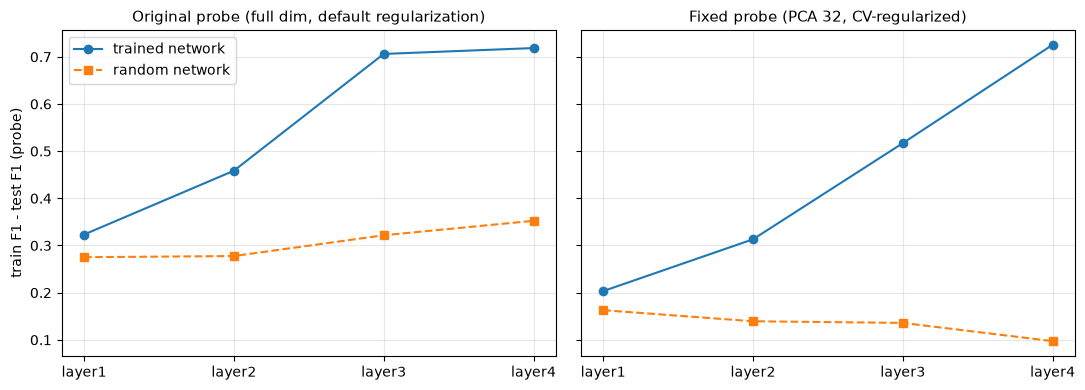


How to read this: if the trained network's gap rises with depth under the fixed probe while the
random network's gap stays flat, the depth pattern reflects learning. If both rise together, the
original Table 2 pattern was mainly a probe artifact and Section 4.5 must be rewritten.


In [10]:
LAYERS = ("layer1", "layer2", "layer3", "layer4")

@torch.no_grad()
def layer_features(m, X):
    acts, hooks = {}, []
    for ln in LAYERS:
        hooks.append(getattr(m.resnet, ln).register_forward_hook(lambda mod, i, o, ln=ln: acts.__setitem__(ln, o)))
    m.eval(); feats = {ln: [] for ln in LAYERS}
    for (bx,) in DataLoader(TensorDataset(torch.from_numpy(X)), batch_size=128, num_workers=0):
        m(bx.to(device))
        for ln in LAYERS: feats[ln].append(acts[ln].mean((2, 3)).cpu().numpy())
    for h in hooks: h.remove()
    return {ln: np.concatenate(v) for ln, v in feats.items()}


def probe_fixed(Ftr,Fte,ytr,yte):
    pipe=Pipeline([("scale",StandardScaler()),("pca",PCA(n_components=PROBE_DIM,random_state=0)),
                   ("clf",LogisticRegression(class_weight="balanced",max_iter=3000))])
    folds=list(TimeSeriesSplit(n_splits=5,gap=H).split(Ftr))
    folds=[(tr,va) for tr,va in folds if len(tr)>PROBE_DIM and len(np.unique(ytr[tr]))>=2]
    scorer=make_scorer(f1_score,average="macro",labels=[0,1,2],zero_division=0)
    if len(folds)>=2:
        search=GridSearchCV(pipe,{"clf__C":np.logspace(-4,2,13)},cv=folds,scoring=scorer,n_jobs=1,error_score="raise")
        search.fit(Ftr,ytr);clf=search.best_estimator_
    else:
        warnings.warn("Too few valid temporal CV splits; use pre-specified C=1")
        clf=pipe.set_params(clf__C=1.0).fit(Ftr,ytr)
    return f1(ytr,clf.predict(Ftr)),f1(yte,clf.predict(Fte)),float(clf.named_steps["clf"].C)

def probe_original(Ftr, Fte, ytr, yte):
    sc = StandardScaler().fit(Ftr)
    clf = LogisticRegression(max_iter=1000).fit(sc.transform(Ftr), ytr)
    return f1(ytr, clf.predict(sc.transform(Ftr))), f1(yte, clf.predict(sc.transform(Fte)))

if RUN_TASK_PROBING:
    done = done_keys("probe_complete", ["market", "year"])
    for name in PROBE_MARKETS:
        d = market_data(name); X = images(name, "gasf")
        for f in d["folds"]:
            if f["year"] not in PROBE_YEARS or (name, str(f["year"])) in done: continue
            ytr, yte = fold_labels(name, f)
            Xtr, Xte = X[f["train_idx"]], X[f["test_idx"]]
            trained = train_model(ResNet18Net, Xtr, ytr, 42)
            net_tr, net_te = f1(ytr, predict(trained, Xtr)), f1(yte, predict(trained, Xte))
            set_seed(42); random_net = ResNet18Net(pretrained=False).to(device)      # untrained control
            block = []
            for tag, net in [("trained", trained), ("random", random_net)]:
                Ftr, Fte = layer_features(net, Xtr), layer_features(net, Xte)
                for ln in LAYERS:
                    a_tr, a_te, C_ = probe_fixed(Ftr[ln], Fte[ln], ytr, yte)
                    o_tr, o_te = probe_original(Ftr[ln], Fte[ln], ytr, yte)
                    block.append(dict(market=name, year=f["year"], network=tag, layer=ln,
                        fixed_train=a_tr, fixed_test=a_te, fixed_C=C_, orig_train=o_tr, orig_test=o_te,
                        net_train_f1=net_tr, net_test_f1=net_te))
            upsert_block("task3_probing", block, ["market","year","network","layer"])
            upsert_block("probe_complete", [dict(market=name,year=f["year"])], ["market","year"])
            del trained, random_net
            print(f"{name} {f['year']}: network train F1={net_tr:.3f} test F1={net_te:.3f}")

res3 = load_ckpt("task3_probing")
if len(res3):
    res3["fixed_gap"] = res3.fixed_train - res3.fixed_test
    res3["orig_gap"] = res3.orig_train - res3.orig_test
    summary = res3.groupby(["network", "layer"])[["orig_train", "orig_test", "orig_gap",
                                                  "fixed_train", "fixed_test", "fixed_gap"]].mean()
    print(summary.round(3))
    fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
    for a, col, ttl in [(ax[0], "orig_gap", "Original probe (full dim, default regularization)"),
                        (ax[1], "fixed_gap", f"Fixed probe (PCA {PROBE_DIM}, CV-regularized)")]:
        for net, st in [("trained", "o-"), ("random", "s--")]:
            s_ = res3[res3.network == net].groupby("layer")[col].mean().reindex(LAYERS)
            a.plot(range(4), s_.values, st, label=f"{net} network")
        a.set_xticks(range(4)); a.set_xticklabels(LAYERS); a.set_title(ttl, fontsize=11); a.grid(alpha=.3)
    ax[0].set_ylabel("train F1 - test F1 (probe)"); ax[0].legend()
    plt.tight_layout(); plt.show()
    print("\nHow to read this: if the trained network's gap rises with depth under the fixed probe while the")
    print("random network's gap stays flat, the depth pattern reflects learning. If both rise together, the")
    print("original Table 2 pattern was mainly a probe artifact and Section 4.5 must be rewritten.")


In [11]:
res1=load_ckpt("task1_seeds")
if len(res1):
    avg=res1.groupby(["market","year","encoding","arch"],as_index=False).img_f1.mean()
    effects=[]
    for old,new in [("gasf","gasf_lvl"),("scalogram","scal_lvl")]:
        for arch in ARCHS:
            a=avg[(avg.encoding==old)&(avg.arch==arch)]
            b=avg[(avg.encoding==new)&(avg.arch==arch)]
            paired=a.merge(b,on=["market","year","arch"],suffixes=("_old","_new"),validate="one_to_one")
            dd=paired.img_f1_new-paired.img_f1_old
            if not len(dd):continue
            p=wilcoxon(dd).pvalue if (dd!=0).any() else 1.0
            effects.append(dict(encoding=new,arch=arch,n=len(dd),mean_diff=dd.mean(),wins=int((dd>0).sum()),p=p))
    effects=pd.DataFrame(effects)
    if len(effects):
        effects["p_holm"]=multipletests(effects.p,method="holm")[1]
        print(effects.to_string(index=False,float_format=lambda v:f"{v:.6g}"))
        effects.to_csv(Path(CKPT_DIR)/"level_preservation_tests.csv",index=False)


encoding     arch  n  mean_diff  wins           p      p_holm
gasf_lvl resnet18 48  0.0519408    35 0.000383574 0.000670322
gasf_lvl smallcnn 48  0.0772677    33  0.00029367 0.000670322
scal_lvl resnet18 48   0.044647    37 0.000223441 0.000670322
scal_lvl smallcnn 48  0.0640262    36 0.000146515  0.00058606


## 8. Frozen image embeddings added to aligned HAR features

A fixed multinomial logistic regression (C=1, class balanced) compares HAR-only versus HAR plus PCA-32 frozen image embeddings. Both use information through t−1. PCA and scalers use purged outer training data only. Holm correction is applied across four encodings separately for F1 and QWK; these are two explicitly separate outcome families. The experiment is exploratory; a notebook comment cannot establish historical preregistration. Volatility-scalogram embeddings are not included here.


In [12]:
from sklearn.metrics import cohen_kappa_score
STACK_ENCODINGS = ["gasf", "scalogram", "gasf_lvl", "scal_lvl"]

@torch.no_grad()
def frozen_embed(name, enc):
    d=market_data(name)
    path = os.path.join(CACHE_DIR, f"{_tag(name)}_{d['data_id']}_{WINDOW}_{FIRST_TEST_YEAR}_{RESNET_INPUT}_{PRETRAINED}_{enc}_frozenR18.npy")
    if os.path.exists(path): return np.load(path)
    X = images(name, enc); set_seed(0)
    w = models.ResNet18_Weights.IMAGENET1K_V1 if PRETRAINED else None
    net = adapt_first_conv(models.resnet18(weights=w), 1); net.fc = nn.Identity(); net = net.to(device).eval()
    out = []
    for (bx,) in DataLoader(TensorDataset(torch.from_numpy(X)), batch_size=256, num_workers=0):
        bx = F.interpolate(bx.to(device), size=(RESNET_INPUT, RESNET_INPUT), mode="bilinear", align_corners=False)
        out.append(net(bx).float().cpu().numpy())
    E = np.concatenate(out); save_npy(path, E); return E

def har_features_lag1(d): return d["X_har"]

def qwk(y, p): return cohen_kappa_score(y, p, labels=[0, 1, 2], weights="quadratic")

def run_stack():
    rows = []
    done=done_keys("task4_stack",["market","year","encoding"])
    for name in MARKETS:
        d = market_data(name); Xh = har_features_lag1(d); ok = np.isfinite(Xh).all(1)
        for enc in STACK_ENCODINGS:
            E = frozen_embed(name, enc)
            for f in d["folds"]:
                if (name,str(f["year"]),enc) in done: continue
                tr, te = f["train_idx"], f["test_idx"]; ytr, yte = fold_labels(name, f)
                mtr, mte = ok[tr], ok[te]
                if mtr.sum() < 100 or mte.sum() < 10: continue
                sh = StandardScaler().fit(Xh[tr][mtr]); Htr, Hte = sh.transform(Xh[tr][mtr]), sh.transform(Xh[te][mte])
                se = StandardScaler().fit(E[tr]); pca = PCA(PROBE_DIM, svd_solver="full").fit(se.transform(E[tr]))
                Ztr, Zte = (pca.transform(se.transform(E[ix][m])) for ix, m in ((tr, mtr), (te, mte)))
                sz = StandardScaler().fit(Ztr); Ztr, Zte = sz.transform(Ztr), sz.transform(Zte)
                yt, ye = ytr[mtr], yte[mte]; res = dict(market=name, year=f["year"], encoding=enc)
                for tag, (A, B_) in {"har": (Htr, Hte), "har_img": (np.hstack([Htr, Ztr]), np.hstack([Hte, Zte])), "img": (Ztr, Zte)}.items():
                    clf = LogisticRegression(C=1.0, class_weight="balanced", max_iter=3000).fit(A, yt); p = clf.predict(B_)
                    res[f"{tag}_f1"] = f1(ye, p); res[f"{tag}_qwk"] = qwk(ye, p)
                rows.append(res)
                upsert_block("task4_stack",[res],["market","year","encoding"])
        print(name, "done")
    return load_ckpt("task4_stack")

if RUN_TASK_STACK:
    stk = run_stack(); stk.to_csv(os.path.join(CKPT_DIR, "task4_stack.csv"), index=False)
    out = []
    for enc, g in stk.groupby("encoding"):
        for met in ["f1", "qwk"]:
            g2 = g.dropna(subset=[f"har_{met}", f"har_img_{met}"]); dd = g2[f"har_img_{met}"] - g2[f"har_{met}"]
            p = wilcoxon(g2[f"har_img_{met}"], g2[f"har_{met}"]).pvalue if (dd != 0).any() else 1.0
            out.append(dict(encoding=enc, metric=met, n=len(g2), mean_diff=dd.mean(), wins=int((dd > 0).sum()), p=p))
    out = pd.DataFrame(out)
    out["p_holm"] = out.groupby("metric").p.transform(lambda x: multipletests(x, method="holm")[1])
    print("HAR+image minus HAR-only (positive = image embedding helps):"); print(out.to_string(index=False,float_format=lambda v:f"{v:.6g}"))
    print("\nreference, mean F1:", stk[["har_f1", "har_img_f1", "img_f1"]].mean().round(3).to_dict())
    out.to_csv(os.path.join(CKPT_DIR, "task4_summary.csv"), index=False)


S&P 500 (US) done


C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\_param_validation.py:218: UndefinedMetricWarning: `y1`, `y2` and `labels` have only one label in common. `cohen_kappa_score` is undefined and set to the value defined by the the `replace_undefined_by` param, which is set to nan.
  return func(*args, **kwargs)
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\_param_validation.py:218: UndefinedMetricWarning: `y1`, `y2` and `labels` have only one label in common. `cohen_kappa_score` is undefined and set to the value defined by the the `replace_undefined_by` param, which is set to nan.
  return func(*args, **kwargs)
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\_param_validation.py:218: UndefinedMetricWarning: `y1`, `y2` and `labels` have only one label in common. `cohen_kappa_score` is undefined and set to the value defined by the the `replace_undefined_by` param, which is set t

EuroStoxx50 (EU) done


C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\_param_validation.py:218: UndefinedMetricWarning: `y1`, `y2` and `labels` have only one label in common. `cohen_kappa_score` is undefined and set to the value defined by the the `replace_undefined_by` param, which is set to nan.
  return func(*args, **kwargs)
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\_param_validation.py:218: UndefinedMetricWarning: `y1`, `y2` and `labels` have only one label in common. `cohen_kappa_score` is undefined and set to the value defined by the the `replace_undefined_by` param, which is set to nan.
  return func(*args, **kwargs)


KOSPI (Korea) done


C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\_param_validation.py:218: UndefinedMetricWarning: `y1`, `y2` and `labels` have only one label in common. `cohen_kappa_score` is undefined and set to the value defined by the the `replace_undefined_by` param, which is set to nan.
  return func(*args, **kwargs)
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\_param_validation.py:218: UndefinedMetricWarning: `y1`, `y2` and `labels` have only one label in common. `cohen_kappa_score` is undefined and set to the value defined by the the `replace_undefined_by` param, which is set to nan.
  return func(*args, **kwargs)
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\_param_validation.py:218: UndefinedMetricWarning: `y1`, `y2` and `labels` have only one label in common. `cohen_kappa_score` is undefined and set to the value defined by the the `replace_undefined_by` param, which is set t

Shanghai Composite (China) done
HAR+image minus HAR-only (positive = image embedding helps):
 encoding metric  n  mean_diff  wins           p     p_holm
     gasf     f1 48 -0.0326647    16  0.00743926  0.0148785
     gasf    qwk 46 -0.0478201    19   0.0651991   0.130398
 gasf_lvl     f1 48 -0.0166267    17    0.098776   0.098776
 gasf_lvl    qwk 45 -0.0395604    18    0.129235   0.130398
 scal_lvl     f1 48 -0.0489263    12  0.00207412 0.00622237
 scal_lvl    qwk 46  -0.087292    13  0.00198411 0.00793643
scalogram     f1 48 -0.0456892    16 0.000894858 0.00357943
scalogram    qwk 46 -0.0690567    15  0.00352795  0.0105839

reference, mean F1: {'har_f1': 0.377, 'har_img_f1': 0.341, 'img_f1': 0.299}


## 9. Exploratory ordinal, portfolio and tail-risk evaluation

No new network training is required here. QWK is reported separately from F1. Holding-period origins are selected globally per market, including across calendar-year boundaries; one common schedule is used for every model and seed. Execution at close t with information through t−1 is a one-day delay. Portfolio simple return is weight × expm1(asset log return), with pre-specified leverage cap and cash at zero return. Drawdown uses compounded wealth including initial wealth 1. Sharpe remains a descriptive annualized holding-period statistic; no significance claim or transaction-cost adjustment is made. Negative portfolio wealth terminates that path.

VaR/ES remain evaluated for the **unmanaged asset's log return**, not the volatility-targeted portfolio. Their regime-based construction is approximate; report coverage and FZ0 rather than inferring calibration from classification accuracy. Buy-and-hold has no artificial VaR/ES values. QWK can be undefined in degenerate folds; sample counts and missing values are retained.


In [15]:
from scipy.stats import chi2
import warnings
ALPHA = 0.025
BASE_MODELS = HEADLINE_BASELINES
BOOT_REPS, BOOT_BLOCK = 2000, 4

def qwk_safe(y, p):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return qwk(y, p)

def risk_from_regime(B, p):
    ytr, tv, tr_ret = B["ytr"], B["tr_y_fwd"], B["tr_fwd_ret"]
    cls = np.array([np.nanmean(tv[ytr == k]) if (ytr == k).any() else np.nanmean(tv) for k in range(3)])
    sig = cls[p]
    # FIX: standardise training returns by the SAME regime-level vol used at forecast time
    z = tr_ret / (np.sqrt(H) * cls[ytr]); z = z[np.isfinite(z)]
    quant = np.quantile(z, ALPHA); es = z[z <= quant].mean()
    weight = np.clip(np.nanmean(tv) / sig, 0, MAX_LEVERAGE)
    return np.sqrt(H) * sig * quant, np.sqrt(H) * sig * es, weight

def fz0(y, v, e):
    valid = np.isfinite(y) & np.isfinite(v) & np.isfinite(e) & (e < 0) & (e <= v)
    if not valid.any(): return np.nan
    y, v, e = y[valid], v[valid], e[valid]
    return float(np.mean(-((y <= v).astype(float)) * (v - y) / (ALPHA * e) + v / e + np.log(-e) - 1))

def kupiec_p(x, n):
    if n <= 0: return np.nan
    pi = x / n
    def loglik(p):
        return (0.0 if n == x else (n - x) * np.log1p(-p)) + (0.0 if x == 0 else x * np.log(p))
    return float(chi2.sf(max(-2 * (loglik(ALPHA) - loglik(pi)), 0.0), 1))

def holding_schedule(name):
    d = market_data(name)
    candidates = np.unique(np.concatenate([f["test_idx"] for f in d["folds"]]))
    selected, last_end = [], -1
    for ix in candidates:
        origin = d["t_use"][ix]
        if origin >= last_end: selected.append(origin); last_end = origin + H
    selected = np.array(selected, dtype=int)
    assert len(selected) < 2 or np.all(np.diff(selected) >= H)
    return set(selected)

def summarize_risk(parts, with_risk=True):
    blocks = [parts[y] for y in sorted(parts)]
    if not blocks:
        return dict(n=0, sharpe=np.nan, maxdd=np.nan, viol=np.nan, kupiec_p=np.nan, fz0=np.nan, bankrupt=False)
    ret, v, e, w, pos = (np.concatenate([b[i] for b in blocks]) for i in range(5))
    order = np.argsort(pos); ret, v, e, w, pos = (a[order] for a in (ret, v, e, w, pos))
    assert len(pos) < 2 or np.all(np.diff(pos) >= H), "Holding periods overlap"
    valid = np.isfinite(ret) & np.isfinite(w)
    ret, v, e, w = ret[valid], v[valid], e[valid], w[valid]
    sr = w * np.expm1(ret); n = len(ret)
    sd = sr.std(ddof=1) if n > 1 else np.nan
    bankrupt = bool(np.any(sr <= -1))
    if bankrupt:
        first = int(np.where(sr <= -1)[0][0]); wealth = np.r_[1.0, np.cumprod(1 + sr[:first]), 0.0]; sharpe = np.nan
    else:
        wealth = np.r_[1.0, np.cumprod(1 + sr)]
        sharpe = float(sr.mean() / sd * np.sqrt(252 / H)) if sd > 0 else np.nan
    peak = np.maximum.accumulate(wealth); maxdd = float(np.max(1 - wealth / peak))
    rv = np.isfinite(v) & np.isfinite(e) & (e < 0) & (e <= v)
    nr = int(rv.sum()) if with_risk else 0
    violations = int((ret[rv] <= v[rv]).sum()) if nr else 0
    return dict(n=n, risk_n=nr, viol=violations / nr if nr else np.nan,
                kupiec_p=kupiec_p(violations, nr) if nr else np.nan,
                fz0=fz0(ret[rv], v[rv], e[rv]) if nr else np.nan,
                sharpe=sharpe, maxdd=maxdd, bankrupt=bankrupt)

def port_series(parts):
    blocks = [parts[y] for y in sorted(parts)]
    ret, v, e, w, pos = (np.concatenate([b[i] for b in blocks]) for i in range(5))
    o = np.argsort(pos)
    return pos[o], (w * np.expm1(ret))[o]

def _sharpe(x):
    s = x.std(ddof=1)
    return x.mean() / s * np.sqrt(252 / H) if s > 0 else np.nan

def boot_sharpe_diff(a, b, reps=BOOT_REPS, block=BOOT_BLOCK, seed=0):
    n = len(a); rng = np.random.default_rng(seed); nb = int(np.ceil(n / block)); diffs = []
    for _ in range(reps):
        st = rng.integers(0, n - block + 1, nb); ix = (st[:, None] + np.arange(block)).ravel()[:n]
        diffs.append(_sharpe(a[ix]) - _sharpe(b[ix]))
    lo, hi = np.nanpercentile(diffs, [2.5, 97.5])
    return _sharpe(a) - _sharpe(b), lo, hi

def run_posthoc(frames):
    res = pd.concat([x for x in frames if len(x)], ignore_index=True).drop_duplicates(["market", "year", "seed", "encoding", "arch"])
    qrows, risk = [], {}
    schedules = {name: holding_schedule(name) for name in MARKETS}
    for (name, year, seed), g in res.groupby(["market", "year", "seed"]):
        if not os.path.exists(bpath(name, year, seed)): continue
        with np.load(bpath(name, year, seed), allow_pickle=True) as pack: B = {k: pack[k] for k in pack.files}
        y = B["y"]; bq = {f"{base}_f1": qwk_safe(y, B[base]) for base in BASE_MODELS}
        ix = np.where(np.isin(B["positions"], list(schedules[name])))[0]
        def add(key, p):
            v, e, w = risk_from_regime(B, p)
            risk.setdefault((name, key, seed), {})[year] = (B["fwd_ret"][ix], v[ix], e[ix], w[ix], B["positions"][ix])
        for base in BASE_MODELS: add(base, B[base])
        nn = len(ix)
        risk.setdefault((name, "buyhold", seed), {})[year] = (B["fwd_ret"][ix], np.full(nn, np.nan), np.full(nn, np.nan), np.ones(nn), B["positions"][ix])
        for row in g.itertuples():
            path = ipath(name, year, seed, row.encoding, row.arch)
            if not os.path.exists(path): continue
            p = np.load(path).astype(int)
            qrows.append(dict(market=name, year=year, seed=seed, encoding=row.encoding, arch=row.arch, img_f1=qwk_safe(y, p), **bq))
            add(f"{row.encoding}/{row.arch}", p)
    return pd.DataFrame(qrows), risk

RUN_POSTHOC = True
if RUN_POSTHOC:
    frames = [load_ckpt("task1_seeds"), load_ckpt("task2_volscal")]
    q, risk = run_posthoc(frames)
    cols = ["img_f1"] + [f"{b}_f1" for b in BASE_MODELS]
    qa = q.groupby(["market", "year", "encoding", "arch"], as_index=False)[cols].mean()
    compare(qa, "Ordinal agreement; undefined pairs omitted", metric="QWK").to_csv(Path(CKPT_DIR) / "posthoc_qwk_tests.csv", index=False)

    rr = pd.DataFrame([dict(market=k[0], model=k[1], seed=k[2], **summarize_risk(b, with_risk=k[1] != "buyhold")) for k, b in risk.items()])
    rr.to_csv(Path(CKPT_DIR) / "posthoc_risk_by_market.csv", index=False)
    market_avg = rr.groupby(["market", "model"], as_index=False).mean(numeric_only=True)
    agg = market_avg.groupby("model")[["sharpe", "maxdd", "viol", "fz0"]].mean().sort_values("sharpe", ascending=False)
    print("\nExploratory gross performance (VaR/ES now standardised by regime vol; target violation rate = 2.5%):")
    print(agg.to_string(float_format=lambda x: f"{x:.4f}")); agg.to_csv(Path(CKPT_DIR) / "posthoc_risk_summary.csv")

    # Paired block bootstrap of the Sharpe difference vs HAR, per market and seed
    rows = []
    for (name, model, seed), parts in risk.items():
        if model in ("har", "buyhold") or (name, "har", seed) not in risk: continue
        pa, a = port_series(parts); pb, b = port_series(risk[(name, "har", seed)])
        if len(a) != len(b) or not np.array_equal(pa, pb) or len(a) < 3 * BOOT_BLOCK: continue
        d, lo, hi = boot_sharpe_diff(a, b)
        rows.append(dict(market=name, model=model, seed=seed, diff=d, lo=lo, hi=hi, excludes_zero=bool(lo > 0 or hi < 0)))
    bt = pd.DataFrame(rows)
    if len(bt):
        summ = bt.groupby("model").agg(mean_diff=("diff", "mean"), share_ci_excl_zero=("excludes_zero", "mean"), n=("diff", "size")).sort_values("mean_diff", ascending=False)
        print("\nSharpe(model) - Sharpe(HAR): moving-block bootstrap 95% CI, per market and seed (exploratory):")
        print(summ.to_string(float_format=lambda x: f"{x:.3f}")); bt.to_csv(Path(CKPT_DIR) / "posthoc_sharpe_bootstrap.csv", index=False)

C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with cg
  warnings.warn(
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regressio


=== Ordinal agreement; undefined pairs omitted (QWK; Holm family = 48 tests) ===
     encoding     arch        vs  n  wins   mean_diff           p     mixed_p  year_cluster_p  year_clusters metric     p_holm  mixed_p_holm  year_cluster_p_holm
         gasf resnet18 pers_lag1 44    18   -0.118472   0.0144094         NaN       0.0211054             12    QWK   0.489921             1             0.654266
         gasf resnet18       har 48    14   -0.138074  0.00117734 0.000874409        0.011739             12    QWK   0.051803     0.0402228             0.410863
         gasf resnet18        rf 48    16  -0.0952202   0.0189909         NaN       0.0361811             12    QWK   0.588719             1              0.93653
         gasf resnet18       tcn 44    16  -0.0863742   0.0692825     0.14104        0.140033             12    QWK          1             1                    1
         gasf smallcnn pers_lag1 44    17   -0.133529  0.00945172         NaN      0.00462215             12

In [16]:
# Stress-class test (class 2 = top volatility tercile). Uses saved predictions only.
def stress_metrics(y, p):
    m = y == 2
    if not m.any(): return dict(f1=np.nan, rec=np.nan, prec=np.nan)
    tp = int(((p == 2) & m).sum()); npred = int((p == 2).sum())
    rec = tp / m.sum(); prec = tp / npred if npred else 0.0
    f1 = 2*prec*rec/(prec+rec) if (prec+rec) else 0.0
    return dict(f1=f1, rec=rec, prec=prec)

def run_stress(frames):
    res = pd.concat([x for x in frames if len(x)], ignore_index=True)\
            .drop_duplicates(["market","year","seed","encoding","arch"])
    rows = []
    for (name, year, seed), g in res.groupby(["market","year","seed"]):
        if not os.path.exists(bpath(name, year, seed)): continue
        with np.load(bpath(name, year, seed), allow_pickle=True) as pack:
            B = {k: pack[k] for k in pack.files}
        y = B["y"].astype(int)
        base = {b: stress_metrics(y, B[b].astype(int)) for b in HEADLINE_BASELINES}
        share = float((y == 2).mean())
        for r in g.itertuples():
            path = ipath(name, year, seed, r.encoding, r.arch)
            if not os.path.exists(path): continue
            im = stress_metrics(y, np.load(path).astype(int))
            row = dict(market=name, year=year, seed=seed, encoding=r.encoding,
                       arch=r.arch, stress_share=share)
            for k in im:
                row[f"img_{k}"] = im[k]
                for b in HEADLINE_BASELINES: row[f"{b}_{k}"] = base[b][k]
            rows.append(row)
    return pd.DataFrame(rows)

S = run_stress([load_ckpt("task1_seeds"), load_ckpt("task2_volscal")])
S.to_csv(Path(CKPT_DIR)/"stress_by_fold.csv", index=False)

print("\nMean stress-class metrics, baselines (all folds):")
b0 = S.drop_duplicates(["market","year","seed"])
print(pd.Series({f"{b}_{k}": b0[f"{b}_{k}"].mean()
                 for b in HEADLINE_BASELINES for k in ("f1","rec","prec")}).unstack().round(3)
      if False else
      b0[[f"{b}_{k}" for b in HEADLINE_BASELINES for k in ("f1","rec","prec")]].mean().round(3).to_string())
print("\nMean stress-class metrics, image models:")
print(S.groupby(["encoding","arch"])[["img_f1","img_rec","img_prec"]].mean().round(3).to_string())

# Wilcoxon + Holm, same protocol as the main table (seed-averaged market-years)
for metric in ["f1", "rec"]:
    cols = [c for c in S.columns if c.endswith("_" + metric)]
    avg = S.groupby(["market","year","encoding","arch"], as_index=False)[cols].mean()
    avg = avg.rename(columns={f"img_{metric}": "img_f1",
                              **{f"{b}_{metric}": f"{b}_f1" for b in HEADLINE_BASELINES}})
    t = compare(avg, f"Stress class, {metric}", metric=f"stress_{metric}")
    t.to_csv(Path(CKPT_DIR)/f"stress_tests_{metric}.csv", index=False)

# Does the image model do better in stress-heavy years? (tercile of stress share per market-year)
sh = S.drop_duplicates(["market","year"])[["market","year","stress_share"]].copy()
sh["regime"] = pd.qcut(sh.stress_share.rank(method="first"), 3, labels=["low","mid","high"])
Sm = S.merge(sh[["market","year","regime"]], on=["market","year"])
Sm["d_har"] = Sm.img_f1 - Sm.har_f1
Sm["d_pers"] = Sm.img_f1 - Sm.pers_lag1_f1
print("\nStress-class F1 difference by stress-share tercile of the test year (image minus baseline):")
print(Sm.groupby(["encoding","arch","regime"], observed=True)[["d_har","d_pers"]].mean().round(3).to_string())


Mean stress-class metrics, baselines (all folds):
pers_lag1_f1      0.450
pers_lag1_rec     0.451
pers_lag1_prec    0.452
har_f1            0.427
har_rec           0.414
har_prec          0.487
rf_f1             0.429
rf_rec            0.461
rf_prec           0.452
tcn_f1            0.346
tcn_rec           0.357
tcn_prec          0.361

Mean stress-class metrics, image models:
                        img_f1  img_rec  img_prec
encoding      arch                               
gasf          resnet18   0.365    0.439     0.413
              smallcnn   0.275    0.310     0.386
gasf_lvl      resnet18   0.355    0.363     0.407
              smallcnn   0.335    0.319     0.382
scal_lvl      resnet18   0.355    0.369     0.382
              smallcnn   0.363    0.368     0.394
scalogram     resnet18   0.326    0.392     0.399
              smallcnn   0.344    0.434     0.418
vol_scal_lvl  resnet18   0.410    0.425     0.436
              smallcnn   0.379    0.379     0.409
vol_scalogram resne

C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with cg
  warnings.warn(
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regressio


=== Stress class, f1 (stress_f1; Holm family = 48 tests) ===
     encoding     arch        vs  n  wins   mean_diff           p     mixed_p  year_cluster_p  year_clusters    metric      p_holm  mixed_p_holm  year_cluster_p_holm
         gasf resnet18 pers_lag1 45    17  -0.0848253   0.0120248         NaN       0.0328196             12 stress_f1    0.324671             1              0.75485
         gasf resnet18       har 45    19  -0.0624899   0.0301305   0.0586158       0.0791102             12 stress_f1    0.693002             1                    1
         gasf resnet18        rf 45    21  -0.0641107   0.0338794         NaN       0.0942479             12 stress_f1    0.711467             1                    1
         gasf resnet18       tcn 45    28   0.0186819    0.771326         NaN        0.643566             12 stress_f1           1             1                    1
         gasf smallcnn pers_lag1 45    12   -0.174139 9.70528e-05  0.00296543      0.00268605             12

C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with cg
  warnings.warn(
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
C:\Users\Asus\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\regressio


=== Stress class, rec (stress_rec; Holm family = 48 tests) ===
     encoding     arch        vs  n  wins   mean_diff           p     mixed_p  year_cluster_p  year_clusters     metric     p_holm  mixed_p_holm  year_cluster_p_holm
         gasf resnet18 pers_lag1 45    20  -0.0119613    0.614744         NaN         0.85316             12 stress_rec          1             1                    1
         gasf resnet18       har 45    22   0.0250471    0.913461         NaN        0.669327             12 stress_rec          1             1                    1
         gasf resnet18        rf 45    21  -0.0217862    0.599081    0.766627        0.745398             12 stress_rec          1             1                    1
         gasf resnet18       tcn 45    29   0.0820381    0.220685         NaN        0.201276             12 stress_rec          1             1                    1
         gasf smallcnn pers_lag1 45    14   -0.141107  0.00677952   0.0429533       0.0385981             

## 10. Robustness checks added in response to review

The cells below add checks that are reported in Section 4.8 and part of Section 4.4 of the paper. They do not change
any result produced above. Cells 10.1 to 10.6 reuse the saved predictions and take minutes; cell 10.7 retrains three
models once and takes about an hour on a GPU.

| Subsection | Question | Paper |
|---|---|---|
| 10.1 | Do the image models still lose when persistence and HAR-RV see only the close-to-close returns? | Table 8 |
| 10.2, 10.6 | How large can the true difference to a baseline be (95% intervals, equivalence within 0.02)? | Table 9 |
| 10.3, 10.5 | How far above a fold-specific chance level is each model? | Table 10 |
| 10.4 | Is the close-to-close result due to the volatility estimator or to the cut-point rule? | Section 4.8 |
| 10.7 | Is the weak fit of the small network caused by the optimizer setting? | Section 4.4 |


### 10.1 to 10.3 Equal-information baselines, intervals and chance level

Run after the Task 1 cells.


In [ ]:
# Robustness checks, part 1 (paper Section 4.8, Tables 8 to 10).
# Uses only the predictions and fold definitions saved by the cells above; nothing is retrained.
# Requires: res1 / compare() from the Task 1 cells, and the saved baseline files (bpath) and image predictions (ipath).
# Writes: closeclose_tests.csv, equivalence_ci.csv, chance_skill.csv (in CKPT_DIR).

HB_BAK = list(HEADLINE_BASELINES)   # restored after the close-to-close comparison below
def mf1(y, p):
    # Macro-F1 over the fixed label set {0,1,2}, computed from the confusion matrix (fast version of f1()).
    # A class that is absent from both y and p scores 0, as with zero_division=0 in f1().
    cm = np.bincount(y*3 + p, minlength=9).reshape(3, 3)
    tp = np.diag(cm); den = cm.sum(0) + cm.sum(1)
    return float(np.where(den > 0, 2*tp/np.maximum(den, 1), 0).mean())
def load_B(name, year):
    # Saved baseline file of one market-year: true labels (y), cut-points (ql, qh) and baseline predictions.
    with np.load(bpath(name, year, SEEDS[0]), allow_pickle=True) as pk:
        return {k: pk[k] for k in pk.files}

# ---- 10.1 Baselines that see only what the images see (Table 8) ----
# Persistence and HAR-RV in the main comparison use open-high-low-close volatility, which the images do not contain.
# Here both are rebuilt from the 64 close-to-close returns of the image window:
#   persistence: 20-day root mean square return, cut at the terciles of its own five-year calibration window;
#   HAR-RV: log forward volatility regressed on log squared returns averaged over 1, 5 and 22 days,
#           classified with the same cut-points (ql, qh) as the label.
rows = []
for name in MARKETS:
    d = market_data(name)
    r2 = d["ret_win"].astype(float)**2
    cc = np.sqrt(r2[:, -20:].mean(1))
    Xc = np.log(np.column_stack([r2[:, -1], r2[:, -5:].mean(1), r2[:, -22:].mean(1)]) + 1e-8)
    for f in d["folds"]:
        tr, te = f["train_idx"], f["test_idx"]
        B = load_B(name, f["year"]); yte = B["y"].astype(int)
        ql, qh = float(B["ql"]), float(B["qh"])
        cal = calib_idx(tr, d["idx"], f["train_end"])
        cl, ch = np.quantile(cc[cal], [1/3, 2/3])
        p_cc = label_q(cc[te], cl, ch)
        reg = LinearRegression().fit(Xc[tr], np.log(d["y_fwd"][tr]))
        h_cc = label_q(np.exp(reg.predict(Xc[te])), ql, qh)
        rows.append(dict(market=name, year=f["year"], pers_cc_f1=f1(yte, p_cc), har_cc_f1=f1(yte, h_cc)))
CC = pd.DataFrame(rows)
print("Mean macro-F1, close-to-close:", CC[["pers_cc_f1","har_cc_f1"]].mean().round(3).to_dict())
res1 = load_ckpt("task1_seeds")
avg = (res1.groupby(["market","year","encoding","arch"], as_index=False)
       [["img_f1","pers_lag1_f1","har_f1","rf_f1","tcn_f1"]].mean().merge(CC, on=["market","year"]))
print("Mean macro-F1, OHLC baselines:", avg[["pers_lag1_f1","har_f1"]].mean().round(3).to_dict())
HEADLINE_BASELINES = ["pers_cc", "har_cc"]
t_cc = compare(avg, "Close-to-close persistence and HAR", metric="f1")
HEADLINE_BASELINES = HB_BAK
t_cc.to_csv(Path(CKPT_DIR)/"closeclose_tests.csv", index=False)

# ---- 10.2 Confidence intervals and equivalence margin (Table 9) ----
# For each image model and baseline: mean macro-F1 difference over market-years, with percentile intervals from a
# bootstrap that resamples whole calendar years (markets share years, so years are the independent units).
# gain_ge_margin_rejected: the 95% interval's upper limit is below +MARGIN, so a gain of MARGIN or more is rejected.
# equivalent_within_margin: the 90% interval lies inside +/-MARGIN (two one-sided tests at the 5% level).
rng = np.random.default_rng(0); MARGIN = 0.02
def year_boot(h, n=4000):
    ys = h.year.unique(); grp = {y: h.loc[h.year == y, "diff"].values for y in ys}
    m = np.array([np.concatenate([grp[y] for y in rng.choice(ys, len(ys))]).mean() for _ in range(n)])
    return np.percentile(m, [2.5, 97.5]), np.percentile(m, [5, 95])
out = []
for (enc, arch), g in avg.groupby(["encoding", "arch"]):
    for base in ["tcn", "har", "pers_lag1", "pers_cc", "har_cc"]:
        h = g.dropna(subset=["img_f1", f"{base}_f1"]).copy(); h["diff"] = h.img_f1 - h[f"{base}_f1"]
        c95, c90 = year_boot(h)
        out.append(dict(encoding=enc, arch=arch, vs=base, mean_diff=h["diff"].mean(), lo95=c95[0], hi95=c95[1],
                        gain_ge_margin_rejected=bool(c95[1] < MARGIN),
                        equivalent_within_margin=bool(c90[0] > -MARGIN and c90[1] < MARGIN)))
EQ = pd.DataFrame(out); EQ.to_csv(Path(CKPT_DIR)/"equivalence_ci.csv", index=False)
print(EQ.round(3).to_string(index=False))

# ---- 10.3 Chance level for macro-F1, seed 42 (Table 10; the circular-shift version over all seeds is in 10.6) ----
# 1/3 is not the right reference when class frequencies differ between test years. For each fold we shuffle each
# model's predictions against the true labels (class frequencies of both are preserved) and average macro-F1 over
# 100 draws. excess = actual macro-F1 minus this chance level; p is a Wilcoxon test over market-years (unadjusted).
rng2 = np.random.default_rng(1); rows = []
for name in MARKETS:
    d = market_data(name)
    for f in d["folds"]:
        B = load_B(name, f["year"]); y = B["y"].astype(int)
        preds = {b: B[b].astype(int) for b in ["pers_lag1", "har", "rf", "tcn"]}
        for enc in MAIN_ENCODINGS + VOL_ENCODINGS:
            for arch in ARCHS:
                pth = ipath(name, f["year"], SEEDS[0], enc, arch)
                if os.path.exists(pth): preds[f"{enc}/{arch}"] = np.load(pth).astype(int)
        for k, p in preds.items():
            ch = np.mean([mf1(y, rng2.permutation(p)) for _ in range(100)])
            rows.append(dict(market=name, year=f["year"], model=k, f1=mf1(y, p), chance=ch))
SK = pd.DataFrame(rows); SK["excess"] = SK.f1 - SK.chance
SK.to_csv(Path(CKPT_DIR)/"chance_skill.csv", index=False)
print(SK.groupby("model")[["f1", "chance", "excess"]].mean().sort_values("excess", ascending=False).round(3).to_string())
print(SK.groupby("model").excess.apply(lambda s: wilcoxon(s).pvalue).round(4).to_string())


### 10.4 to 10.7 Calibration control, circular-shift chance level, unrounded intervals and optimizer control

Run after the previous cell.


In [ ]:
# Robustness checks, part 2 (paper Sections 4.4 and 4.8).
# Run after part 1: it reuses CC, avg, res1, mf1, load_B and year_boot defined there.
# 10.4 to 10.6 use saved files only (minutes). 10.7 retrains SmallCNN and TCN once (about an hour on a GPU);
# set RUN_LR_CONTROL = False to skip it. Results are checkpointed, so an interrupted run resumes.
# Writes: calibration_control.csv, chance_circular.csv, equivalence_ci_unrounded.csv,
#         task5_lrcontrol.csv, lrcontrol_vs_original.csv (in CKPT_DIR).

# ---- 10.4 Calibration control for the close-to-close persistence rule (Section 4.8) ----
# The close-to-close persistence rule changes two things at once: the volatility estimator and the way cut-points
# are set. To separate them, persistence is also run on trailing Yang-Zhang volatility with its own cut-points.
#   calibration effect = (YZ, own cut-points) - (YZ, label cut-points)       [main persistence rule]
#   estimator effect   = (close-to-close, own cut-points) - (YZ, own cut-points)
#   HAR estimator effect = close-to-close HAR - range-based HAR, both with the label cut-points
rows = []
for name in MARKETS:
    d = market_data(name)
    for f in d["folds"]:
        tr, te = f["train_idx"], f["test_idx"]
        y = load_B(name, f["year"])["y"].astype(int)
        cal = calib_idx(tr, d["idx"], f["train_end"])
        zl, zh = np.quantile(d["y_trail_lag1"][cal], [1/3, 2/3])
        rows.append(dict(market=name, year=f["year"],
                         pers_own_f1=f1(y, label_q(d["y_trail_lag1"][te], zl, zh))))
base0 = res1[res1.seed == SEEDS[0]].drop_duplicates(["market", "year"])[["market", "year", "pers_lag1_f1", "har_f1"]]
P = pd.DataFrame(rows).merge(CC, on=["market", "year"]).merge(base0, on=["market", "year"])
P.to_csv(Path(CKPT_DIR)/"calibration_control.csv", index=False)
print("Mean macro-F1:\n", P[["pers_lag1_f1", "pers_own_f1", "pers_cc_f1", "har_f1", "har_cc_f1"]].mean().round(4).to_string())
for a, b, what in [("pers_own_f1", "pers_lag1_f1", "calibration effect (same YZ estimator)"),
                   ("pers_cc_f1", "pers_own_f1", "estimator effect (same own-calibration rule)"),
                   ("har_cc_f1", "har_f1", "HAR estimator effect (same label cut-points)")]:
    dd = P[a] - P[b]
    print(f"{what}: {dd.mean():+.4f}, Wilcoxon p = {wilcoxon(dd).pvalue if (dd != 0).any() else 1:.4f}")

# ---- 10.5 Chance level that respects serial dependence (Table 10), all seeds ----
# Besides shuffling predictions (which destroys their autocorrelation), shift each prediction series circularly by
# at least H = 20 days against the labels. This keeps the persistence of the forecasts and gives a stricter reference.
# Results are averaged over seeds within market-year; Holm correction is applied over the models.
rng3 = np.random.default_rng(2); rows = []
for name in MARKETS:
    d = market_data(name)
    for f in d["folds"]:
        for seed in SEEDS:
            if not os.path.exists(bpath(name, f["year"], seed)): continue
            with np.load(bpath(name, f["year"], seed), allow_pickle=True) as pk: B = {k: pk[k] for k in pk.files}
            y = B["y"].astype(int); n = len(y)
            preds = {b: B[b].astype(int) for b in ["pers_lag1", "har", "rf", "tcn"]}
            for enc in MAIN_ENCODINGS + VOL_ENCODINGS:
                for arch in ARCHS:
                    pth = ipath(name, f["year"], seed, enc, arch)
                    if os.path.exists(pth): preds[f"{enc}/{arch}"] = np.load(pth).astype(int)
            shifts = rng3.integers(H, n - H, 100) if n > 2 * H else []
            for k, p in preds.items():
                rows.append(dict(market=name, year=f["year"], seed=seed, model=k, f1=mf1(y, p),
                                 perm=np.mean([mf1(y, rng3.permutation(p)) for _ in range(100)]),
                                 circ=np.mean([mf1(y, np.roll(p, s)) for s in shifts]) if len(shifts) else np.nan))
CH = pd.DataFrame(rows); CH.to_csv(Path(CKPT_DIR)/"chance_circular.csv", index=False)
CHm = CH.groupby(["market", "year", "model"], as_index=False)[["f1", "perm", "circ"]].mean()
CHm["ex_perm"] = CHm.f1 - CHm.perm; CHm["ex_circ"] = CHm.f1 - CHm.circ
summ = CHm.groupby("model")[["f1", "perm", "circ", "ex_perm", "ex_circ"]].mean()
summ["p_circ"] = CHm.groupby("model").ex_circ.apply(lambda s: wilcoxon(s.dropna()).pvalue)
summ["p_circ_holm"] = multipletests(summ.p_circ.fillna(1), method="holm")[1]
summ["n"] = CHm.groupby("model").ex_circ.count()
print(summ.sort_values("ex_circ", ascending=False).round(4).to_string())

# ---- 10.6 Unrounded 95% and 90% year-bootstrap intervals (Table 9) ----
# Same procedure and random seed as in 10.2, saved with full precision so that comparisons with the +/-0.02 margin
# can be checked without rounding.
rng = np.random.default_rng(0); out = []
for (enc, arch), g in avg.groupby(["encoding", "arch"]):
    for base in ["tcn", "har", "pers_lag1", "pers_cc", "har_cc"]:
        h = g.dropna(subset=["img_f1", f"{base}_f1"]).copy(); h["diff"] = h.img_f1 - h[f"{base}_f1"]
        c95, c90 = year_boot(h)
        out.append(dict(encoding=enc, arch=arch, vs=base, mean_diff=h["diff"].mean(),
                        lo95=c95[0], hi95=c95[1], lo90=c90[0], hi90=c90[1]))
EQ2 = pd.DataFrame(out); EQ2.to_csv(Path(CKPT_DIR)/"equivalence_ci_unrounded.csv", index=False)
print(EQ2[EQ2.encoding.isin(["gasf_lvl", "scal_lvl"])].to_string(index=False, float_format=lambda v: f"{v:.5f}"))

# ---- 10.7 Optimizer control (Section 4.4) ----
# The main runs use one optimizer setting (Adam, lr 5e-5, 10 epochs) for every network. That is suitable for
# fine-tuning ResNet18 but may under-train networks started from scratch. As a control, SmallCNN (on the two
# fixed-scale encodings) and the TCN are retrained with lr 1e-3 and 30 epochs, seed 42, and compared with the
# main runs. This is one alternative setting, not a hyperparameter search.
RUN_LR_CONTROL = True
if RUN_LR_CONTROL:
    LR_BAK, LR, ck = LR, 1e-3, "task5_lrcontrol"
    done = done_keys(ck, ["market", "year", "seed", "model"])
    try:
        for name in MARKETS:
            d = market_data(name)
            for f in d["folds"]:
                ytr, yte = fold_labels(name, f); tr, te = f["train_idx"], f["test_idx"]
                jobs = [(enc, SmallCNN, images(name, enc)) for enc in ["gasf_lvl", "scal_lvl"]] + [("tcn", TCN, d["X_seq"])]
                for key, make, X in jobs:
                    k = (name, str(f["year"]), str(SEEDS[0]), key)
                    if k in done: continue
                    t0 = time.time()
                    m = train_model(make, X[tr], ytr, SEEDS[0], epochs=30)
                    row = dict(market=name, year=f["year"], seed=SEEDS[0], model=key,
                               test_f1=f1(yte, predict(m, X[te])), train_f1=f1(ytr, predict(m, X[tr])))
                    upsert_block(ck, [row], ["market", "year", "seed", "model"]); done.add(k); del m
                    print(f"{name[:12]:12s} {f['year']} {key:9s} train={row['train_f1']:.3f} test={row['test_f1']:.3f} ({time.time()-t0:.0f}s)")
    finally:
        LR = LR_BAK

L = load_ckpt("task5_lrcontrol")
if len(L):
    o1 = res1[(res1.seed == SEEDS[0]) & (res1.arch == "smallcnn") & res1.encoding.isin(["gasf_lvl", "scal_lvl"])]
    o1 = o1[["market", "year", "encoding", "img_f1", "train_f1"]].rename(
        columns={"encoding": "model", "img_f1": "test_f1_orig", "train_f1": "train_f1_orig"})
    o2 = base0[["market", "year"]].merge(res1[res1.seed == SEEDS[0]].drop_duplicates(["market", "year"])[["market", "year", "tcn_f1"]])
    o2 = o2.assign(model="tcn").rename(columns={"tcn_f1": "test_f1_orig"})
    M = L.merge(pd.concat([o1, o2]), on=["market", "year", "model"])
    M.to_csv(Path(CKPT_DIR)/"lrcontrol_vs_original.csv", index=False)
    print(M.groupby("model")[["train_f1", "train_f1_orig", "test_f1", "test_f1_orig"]].mean().round(4).to_string())
    for mdl, g in M.groupby("model"):
        dd = g.test_f1 - g.test_f1_orig
        print(f"{mdl}: test change {dd.mean():+.4f}, Wilcoxon p = {wilcoxon(dd).pvalue:.4f}")
    W = L.pivot_table(index=["market", "year"], columns="model", values="test_f1").reset_index().merge(base0, on=["market", "year"])
    for enc in ["gasf_lvl", "scal_lvl"]:
        for ref in ["tcn", "har_f1", "pers_lag1_f1"]:
            dd = (W[enc] - W[ref]).dropna()
            print(f"{enc} (lr 1e-3) minus {ref}: {dd.mean():+.4f}, Wilcoxon p = {wilcoxon(dd).pvalue:.4f}")
